# PHASE 1

In [2]:
# IMPORT LIBRARIES
import pandas as pd
import numpy as np

# LOAD DATASET
df = pd.read_csv("mental-heath-in-tech-2016_20161114.csv")
print("Dataset loaded successfully.")



Dataset loaded successfully.


In [3]:
import pandas as pd

# 1. Define the variable
num_cols = df.select_dtypes("number").columns

#2. Build summary
stats_num = pd.DataFrame({
    "count":   df[num_cols].count(),
    "missing": df[num_cols].isna().sum(),
    "mean":    df[num_cols].mean().round(2),
    "median":  df[num_cols].median(),
    "std":     df[num_cols].std().round(2),
    "min":     df[num_cols].min(),
    "q1":      df[num_cols].quantile(0.25),
    "q3":      df[num_cols].quantile(0.75),
    "max":     df[num_cols].max(),
    "skew":    df[num_cols].skew().round(2),
}).T

print("NUMERIC DESCRIPTIVE STATS:")
print(stats_num)

NUMERIC DESCRIPTIVE STATS:
         Are you self-employed?  \
count                    1433.0   
missing                     0.0   
mean                        0.2   
median                      0.0   
std                         0.4   
min                         0.0   
q1                          0.0   
q3                          0.0   
max                         1.0   
skew                        1.5   

         Is your employer primarily a tech company/organization?  \
count                                              1146.00         
missing                                             287.00         
mean                                                  0.77         
median                                                1.00         
std                                                   0.42         
min                                                   0.00         
q1                                                    1.00         
q3                                         

In [4]:
cat_cols = df.select_dtypes(include=["object", "string", "category"]).columns

def top_freq(s):
    vc = s.value_counts()
    return int(vc.iloc[0]) if len(vc) else 0

stats_cat = pd.DataFrame({
    "count":     df[cat_cols].count(),
    "missing":   df[cat_cols].isna().sum(),
    "nunique":   df[cat_cols].nunique(),
    "top":       df[cat_cols].mode().iloc[0],
    "top_freq":  [top_freq(df[c]) for c in cat_cols],
}).sort_values("nunique", ascending=False)

stats_cat["top_%"] = (stats_cat["top_freq"] / stats_cat["count"] * 100).round(2)

print("\nCATEGORICAL DESCRIPTIVE STATS:")
print(stats_cat.head(20))


CATEGORICAL DESCRIPTIVE STATS:
                                                    count  missing  nunique  \
Why or why not?                                      1095      338     1085   
Why or why not?.1                                    1126      307     1080   
Which of the following best describes your work...   1433        0      264   
If yes, what condition(s) have you been diagnos...    568      865      128   
If so, what condition(s) were you diagnosed with?     711      722      116   
If maybe, what condition(s) do you believe you ...    322     1111       99   
What is your gender?                                 1430        3       70   
What country do you work in?                         1433        0       53   
What country do you live in?                         1433        0       53   
What US state or territory do you work in?            851      582       48   
What US state or territory do you live in?            840      593       47   
How many employees d

In [5]:
# VALUE COUNTS (detailed)

for col in cat_cols[:5]:
    print(f"\n{col}")
    print(df[col].value_counts().head(10).to_string())


How many employees does your company or organization have?
How many employees does your company or organization have?
26-100            292
More than 1000    256
100-500           248
6-25              210
500-1000           80
1-5                60

Does your employer provide mental health benefits as part of healthcare coverage?
Does your employer provide mental health benefits as part of healthcare coverage?
Yes                                531
I don't know                       319
No                                 213
Not eligible for coverage / N/A     83

Do you know the options for mental health care available under your employer-provided coverage?
Do you know the options for mental health care available under your employer-provided coverage?
No               354
I am not sure    352
Yes              307

Has your employer ever formally discussed mental health (for example, as part of a wellness campaign or other official communication)?
Has your employer ever formally disc

In [6]:
# SHAPE

print(f"Shape: {df.shape}")


Shape: (1433, 63)


In [7]:
# DATATYPES
print(df.dtypes.value_counts())

str        56
int64       4
float64     3
Name: count, dtype: int64


In [8]:
# MISSING VALUES

print(df.isna().sum().sort_values(ascending=False).head(20))

If you have revealed a mental health issue to a client or business contact, do you believe this has impacted you negatively?                                                        1289
If yes, what percentage of your work time (time performing primary or secondary job functions) is affected by a mental health issue?                                                1229
Is your primary role within your company related to tech/IT?                                                                                                                        1170
Do you have medical coverage (private insurance or state-provided) which includes treatment of  mental health issues?                                                               1146
If you have been diagnosed or treated for a mental health disorder, do you ever reveal this to clients or business contacts?                                                        1146
If you have been diagnosed or treated for a mental health disorder, do you 

In [9]:
# CHECK DUPLICATE ROWS

print(f"Duplicate rows: {df.duplicated().sum()}")

Duplicate rows: 0


In [10]:
# CHECK DUPLICATE COLUMNS

print(f"Duplicate cols: {df.columns.duplicated().sum()}")

Duplicate cols: 0


In [11]:
# NUMERIC RANGES

num_cols = df.select_dtypes("number").columns
print(df[num_cols].describe().T[["min", "max"]])

                                                    min    max
Are you self-employed?                              0.0    1.0
Is your employer primarily a tech company/organ...  0.0    1.0
Is your primary role within your company relate...  0.0    1.0
Do you have medical coverage (private insurance...  0.0    1.0
Do you have previous employers?                     0.0    1.0
Have you ever sought treatment for a mental hea...  0.0    1.0
What is your age?                                   3.0  323.0


In [12]:
# CATEGORICAL CARDINALITY (Categorical variables)

cat_cols = df.select_dtypes(include=["object", "string", "category"]).columns
print(df[cat_cols].nunique().sort_values(ascending=False).head(20))

Why or why not?                                                                                                                   1085
Why or why not?.1                                                                                                                 1080
Which of the following best describes your work position?                                                                          264
If yes, what condition(s) have you been diagnosed with?                                                                            128
If so, what condition(s) were you diagnosed with?                                                                                  116
If maybe, what condition(s) do you believe you have?                                                                                99
What is your gender?                                                                                                                70
What country do you work in?                           

In [13]:
# TINY CATEGORIES (categories with <20 respondents)

for col in cat_cols:
    vc = df[col].value_counts()
    tiny = vc[vc < 20]
    if len(tiny):
        print(f"{col}: {len(tiny)} tiny categories")

If you have been diagnosed or treated for a mental health disorder, do you ever reveal this to clients or business contacts?: 1 tiny categories
If you have been diagnosed or treated for a mental health disorder, do you ever reveal this to coworkers or employees?: 2 tiny categories
Do you believe your productivity is ever affected by a mental health issue?: 1 tiny categories
If yes, what percentage of your work time (time performing primary or secondary job functions) is affected by a mental health issue?: 1 tiny categories
Why or why not?: 1085 tiny categories
Why or why not?.1: 1080 tiny categories
If yes, what condition(s) have you been diagnosed with?: 123 tiny categories
If maybe, what condition(s) do you believe you have?: 96 tiny categories
If so, what condition(s) were you diagnosed with?: 110 tiny categories
If you have a mental health issue, do you feel that it interferes with your work when NOT being treated effectively?: 1 tiny categories
What is your gender?: 62 tiny catego

In [14]:
# PLACEHOLDERS (detect and show which type in each column)

placeholders = {
    "-1", "999", "n/a", "unknown", "?", "-", "??", "???",
    "na", "none", "null", "nan", "not sure", "don't know", "dont know",
    ".", "..", "...", "x", "xx",
}

print(f"{'column':<40} {'total':>6}  breakdown")
print("-" * 100)

for col in cat_cols:
    s = df[col].dropna().astype(str).str.strip().str.lower()
    hits = s[s.isin(placeholders)]

    if len(hits):
        # count each placeholder value
        vc = hits.value_counts()
        detail = "  ".join(f"'{k}'×{v}" for k, v in vc.items())
        print(f"{col:<40} {len(hits):>6}  {detail}")

column                                    total  breakdown
----------------------------------------------------------------------------------------------------
Why or why not?                               3  '?'×1  '.'×1  'not sure'×1
Why or why not?.1                             1  'na'×1


In [15]:
# WHITESPACE

checked = 0
issues = 0

for col in cat_cols[:10]:
    s = df[col].dropna().astype(str)
    ws = (s != s.str.strip()).sum()
    checked += 1
    if ws:
        issues += 1
        print(f"{col}: {ws} whitespace issues")

print(f"\n✅ Checked {checked} columns — {issues} with whitespace")


✅ Checked 10 columns — 0 with whitespace


In [16]:
# CHARTS — SETUP

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Okabe-Ito colourblind-safe palette
CB = {
    "blue":      "#0072B2",
    "orange":    "#E69F00",
    "green":     "#009E73",
    "red":       "#D55E00",
    "purple":    "#CC79A7",
    "sky":       "#56B4E9",
    "yellow":    "#F0E442",
    "grey":      "#999999",
}

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 150,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "savefig.bbox": "tight",
})

# ─── resolve column names from the raw CSV ───
TARGET = "Have you been diagnosed with a mental health condition by a medical professional?"
AGE    = "What is your age?"
GENDER = "What is your gender?"
SIZE   = "How many employees does your company or organization have?"

# sanity print
print(f"Target: {TARGET}  |  Age: {AGE}  |  Gender: {GENDER}  |  Size: {SIZE}")
print(f"Rows: {len(df):,}  |  Columns: {len(df.columns)}")

Target: Have you been diagnosed with a mental health condition by a medical professional?  |  Age: What is your age?  |  Gender: What is your gender?  |  Size: How many employees does your company or organization have?
Rows: 1,433  |  Columns: 63


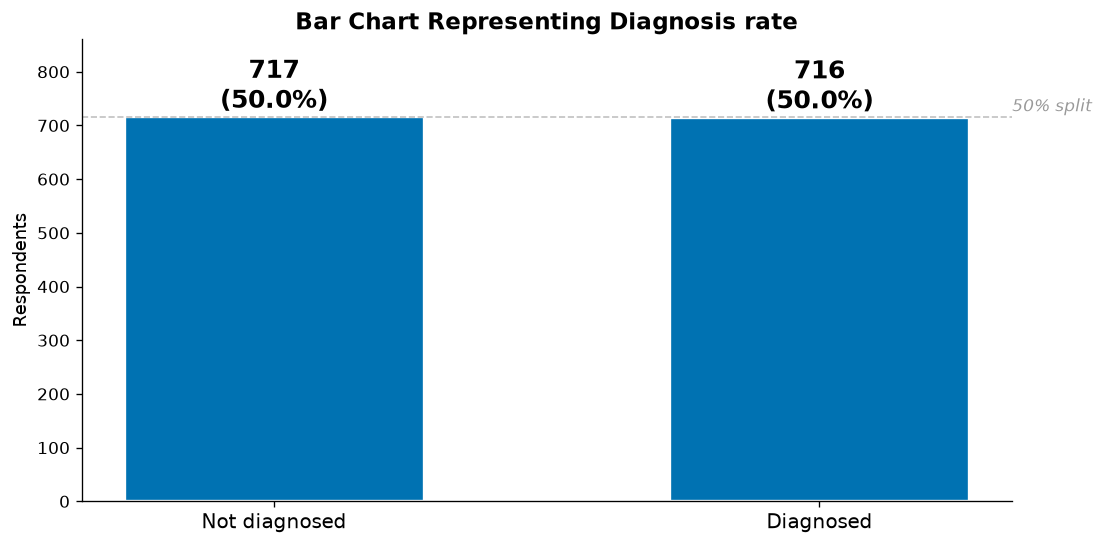

In [17]:
# PHASE 1 — CHART 1: DIAGNOSIS RATE

vc = df[TARGET].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(range(len(vc)), vc.values,
              color=CB["blue"], edgecolor="white",
              linewidth=2, width=0.55)

for bar, v in zip(bars, vc.values):
    pct = v / len(df) * 100
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
            f"{v:,}\n({pct:.1f}%)",
            ha="center", va="bottom", fontsize=15, fontweight="bold")

ax.set_xticks(range(len(vc)))
ax.set_xticklabels(["Not diagnosed", "Diagnosed"], fontsize=12)
ax.set_ylabel("Respondents")
ax.set_title("Bar Chart Representing Diagnosis rate")
ax.set_ylim(0, max(vc.values) * 1.2)
ax.axhline(len(df) / 2, color=CB["grey"], ls="--", lw=1, alpha=0.6)
ax.text(1.5, len(df)/2 + 10, "50% split", ha="right",
        fontsize=10, color=CB["grey"], style="italic")
ax.set_axisbelow(True)

plt.savefig("phase1_01_diagnosis.png")
plt.show()

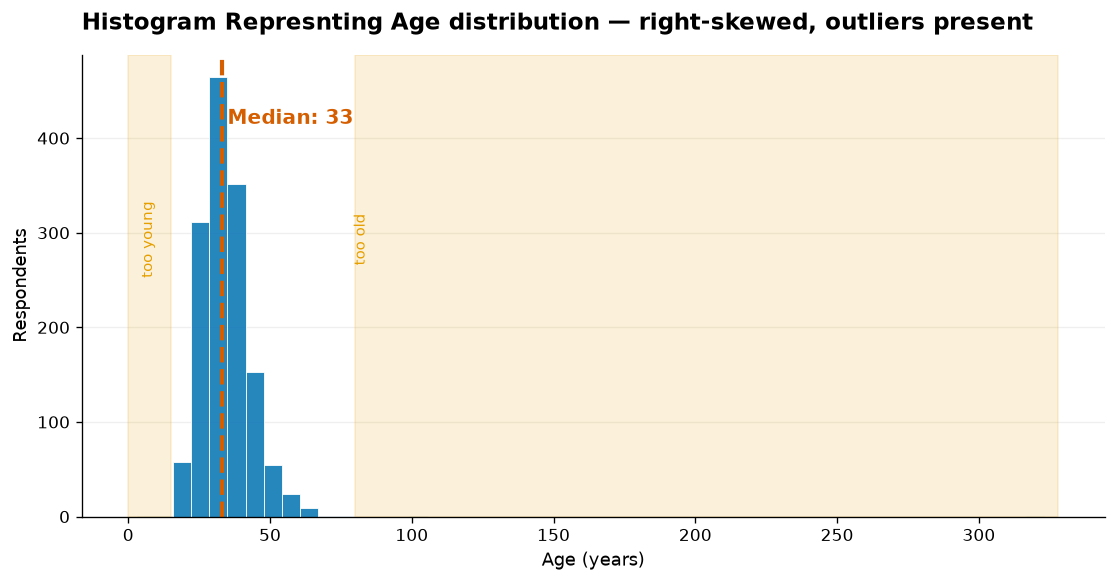

Total rows:         1433
Missing (NaN):      0
Min:                3
Max:                323
Median:             33
Q1–Q3:              28–39

Impossible values
  age < 15:         1 rows
  age > 80:         2 rows
  age > 100:        1 rows


In [18]:
# PHASE 1 - CHART 2: AGE DISTRIBUTION 

import pandas as pd
import matplotlib.pyplot as plt

# coerce to numeric only so we can plot — but do NOT filter
ages = pd.to_numeric(df[AGE], errors="coerce")

fig, ax = plt.subplots(figsize=(11, 5))

# ── full raw histogram ──
ax.hist(ages.dropna(), bins=50, color=CB["blue"],
        edgecolor="white", linewidth=0.6, alpha=0.85)

# ── median line (on raw data) ──
median = ages.median()
ax.axvline(median, color=CB["red"], lw=2.5, ls="--")
ax.text(median + 2, ax.get_ylim()[1] * 0.85,
        f"Median: {median:.0f}", color=CB["red"],
        fontsize=12, fontweight="bold")

# ── mark impossible-value boundaries ──
ax.axvspan(0, 15, color=CB["orange"], alpha=0.15)
ax.axvspan(80, ages.max() + 5, color=CB["orange"], alpha=0.15)
ax.text(7, ax.get_ylim()[1] * 0.6, "too young", ha="center",
        fontsize=9, color=CB["orange"], rotation=90, va="center")
ax.text(82, ax.get_ylim()[1] * 0.6, "too old", ha="center",
        fontsize=9, color=CB["orange"], rotation=90, va="center")

ax.set_xlabel("Age (years)")
ax.set_ylabel("Respondents")
ax.set_title("Histogram Represnting Age distribution — right-skewed, outliers present",
             loc="left", pad=15)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.savefig("phase1_02_age.png")
plt.show()

# ── report the raw values ──
print(f"Total rows:         {len(ages)}")
print(f"Missing (NaN):      {ages.isna().sum()}")
print(f"Min:                {ages.min():.0f}")
print(f"Max:                {ages.max():.0f}")
print(f"Median:             {median:.0f}")
print(f"Q1–Q3:              {ages.quantile(0.25):.0f}–{ages.quantile(0.75):.0f}")
print(f"\nImpossible values")
print(f"  age < 15:         {(ages < 15).sum()} rows")
print(f"  age > 80:         {(ages > 80).sum()} rows")
print(f"  age > 100:        {(ages > 100).sum()} rows")

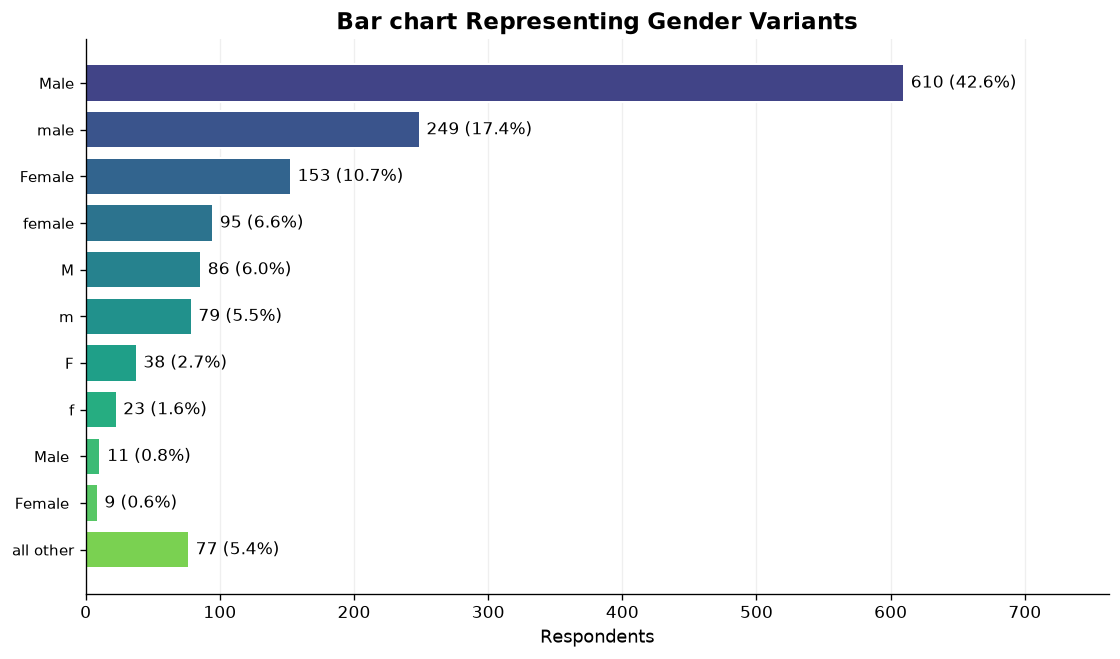

Unique raw strings: 70
Top value:  'Male' (610)


In [19]:
# PHASE 1 - CHART 3: GENDER DISTRIBUTION

vc = df[GENDER].value_counts()

top = vc.head(10)
others = vc.iloc[10:].sum() if len(vc) > 10 else 0

labels = list(top.index) + (["all other"] if others else [])
values = list(top.values) + ([others] if others else [])

fig, ax = plt.subplots(figsize=(11, 6))

colors = plt.cm.viridis(np.linspace(0.2, 0.8, len(labels)))
bars = ax.barh(range(len(labels)), values[::-1],
               color=colors[::-1], edgecolor="white", linewidth=1.2)

for bar, v in zip(bars, values[::-1]):
    pct = v / len(df) * 100
    ax.text(bar.get_width() + 5, bar.get_y() + bar.get_height()/2,
            f"{v:,} ({pct:.1f}%)", va="center", fontsize=10)

ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels[::-1], fontsize=9)
ax.set_xlabel("Respondents")
ax.set_title("Bar chart Representing Gender Variants")
ax.set_xlim(0, max(values) * 1.25)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.savefig("phase1_03_gender.png")
plt.show()

print(f"Unique raw strings: {len(vc)}")
print(f"Top value:  {vc.index[0]!r} ({vc.iloc[0]})")

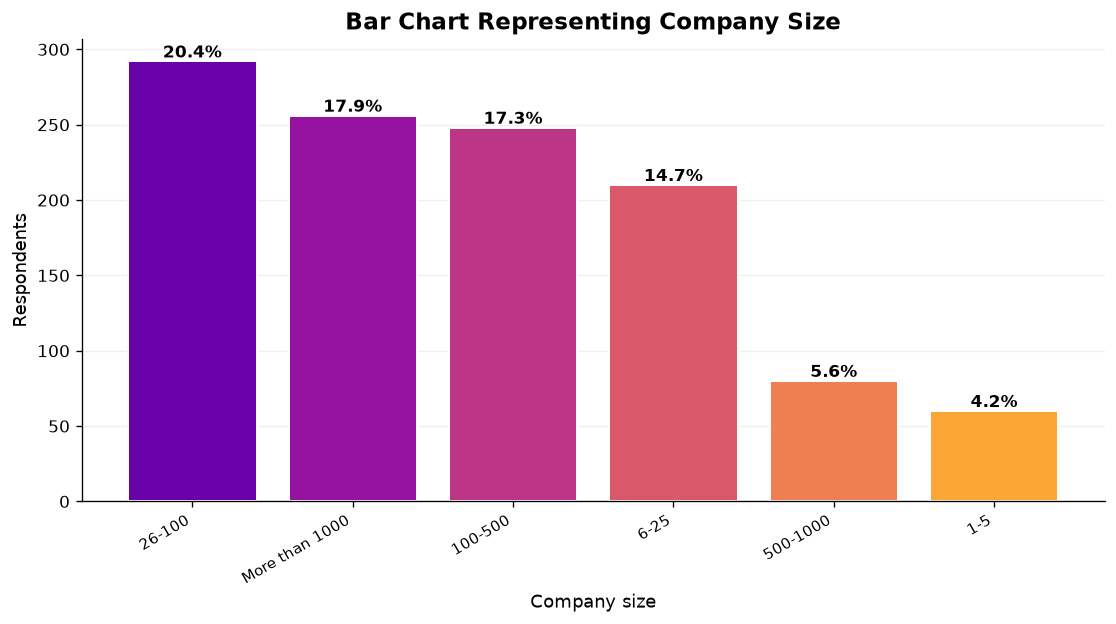

Top sizes:
How many employees does your company or organization have?
26-100            292
More than 1000    256
100-500           248
6-25              210
500-1000           80
1-5                60


In [20]:
# PHASE 1 - CHART 4: COMPANY SIZE DISTRIBUTION

vc = df[SIZE].value_counts()

fig, ax = plt.subplots(figsize=(11, 5))

colors = plt.cm.plasma(np.linspace(0.2, 0.8, len(vc)))
bars = ax.bar(range(len(vc)), vc.values,
              color=colors, edgecolor="white", linewidth=1.2)

for bar, v in zip(bars, vc.values):
    pct = v / len(df) * 100
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
            f"{pct:.1f}%", ha="center", va="bottom",
            fontsize=10, fontweight="bold")

ax.set_xticks(range(len(vc)))
ax.set_xticklabels(vc.index, fontsize=9, rotation=30, ha="right")
ax.set_ylabel("Respondents")
ax.set_xlabel("Company size")
ax.set_title("Bar Chart Representing Company Size")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.savefig("phase1_04_company_size.png")
plt.show()

print("Top sizes:")
print(vc.to_string())

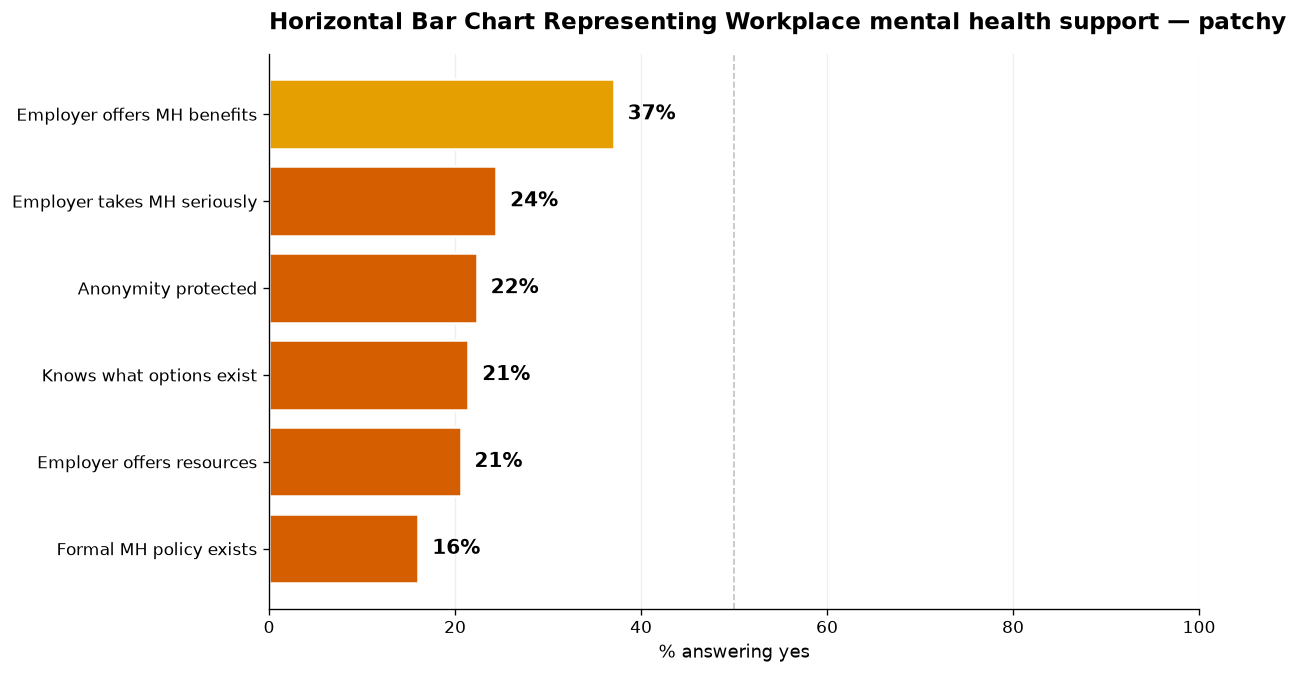


Support rates:
  Employer offers MH benefits              37%
  Employer takes MH seriously              24%
  Anonymity protected                      22%
  Knows what options exist                 21%
  Employer offers resources                21%
  Formal MH policy exists                  16%


In [21]:
# PHASE 1 - CHART 5: WORKPLACE SUPPORT PREVALENCE

SUPPORT = {
    "Does your employer provide mental health benefits as part of healthcare coverage?":   "Employer offers MH benefits",
    "Do you know the options for mental health care available under your employer-provided coverage?":   "Knows what options exist",
    "Has your employer ever formally discussed mental health (for example, as part of a wellness campaign or other official communication)?":   "Formal MH policy exists",
    "Does your employer offer resources to learn more about mental health concerns and options for seeking help?":   "Employer offers resources",
    "Is your anonymity protected if you choose to take advantage of mental health or substance abuse treatment resources provided by your employer?":   "Anonymity protected",
    "Do you feel that your employer takes mental health as seriously as physical health?":  "Employer takes MH seriously",
}

rates = {}
for col, label in SUPPORT.items():
    if col not in df.columns:
        continue
    s = df[col]
    if pd.api.types.is_numeric_dtype(s):
        rate = s.mean()
    else:
        rate = s.astype(str).str.lower().isin(["yes", "1", "true"]).mean()
    if pd.notna(rate):
        rates[label] = rate

rates = dict(sorted(rates.items(), key=lambda x: x[1]))

fig, ax = plt.subplots(figsize=(10, 6))

labels = list(rates.keys())
values = [rates[k] * 100 for k in labels]

colors = [CB["red"] if v < 30 else CB["orange"] if v < 60 else CB["green"]
          for v in values]

bars = ax.barh(range(len(labels)), values,
               color=colors, edgecolor="white", linewidth=1.5)

for bar, v in zip(bars, values):
    ax.text(v + 1.5, bar.get_y() + bar.get_height()/2,
            f"{v:.0f}%", va="center", fontsize=12, fontweight="bold")

ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels, fontsize=10)
ax.set_xlabel("% answering yes")
ax.set_title("Horizontal Bar Chart Representing Workplace mental health support — patchy",
             loc="left", pad=15)
ax.set_xlim(0, 100)
ax.axvline(50, color=CB["grey"], lw=1, ls="--", alpha=0.6)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.savefig("phase1_05_workplace_support.png")
plt.show()

print("\nSupport rates:")
for k, v in sorted(rates.items(), key=lambda x: -x[1]):
    print(f"  {k:<40} {v*100:.0f}%")

# PHASE 2 & 3

## Phase 2 — Planning the Cleaning Strategy

Based on the Phase 1 exploration, the following decisions were made before preprocessing:

### 1. Columns to Keep
*   **Core demographics:** age, gender, country of residence
*   **Workplace support:** benefits, resources, anonymity, formal policy, comfort discussing
*   **Personal history:** diagnosis, treatment, family history
*   **Employment:** company size, self-employment, role

### 2. Columns to Drop
| Column | Reason |
| :--- | :--- |
| Country of work | 89.8% identical to country of residence — redundant |
| US state (live/work) | Subset of country; 41% missing; too granular |
| Some redundant workplace questions | High overlap with other columns |

### 3. Cleaning Rules Needed
*   **Age:** Coerce to numeric; flag values `< 15` or `> 80` as NaN (implausible).
*   **Gender:** Map 70+ raw strings to 5 canonical categories.
*   **Country:** Consolidate 53 categories into 5 groups (US, UK, Canada, DE+NL, Other).
*   **Roles:** Split 264 pipe-separated combinations into 12 binary columns; merge rare roles.
*   **Missing Values:** Impute numeric with median, categorical with "unknown".

### 4. Encoding Rules Needed
*   **Binary (Yes/No):** Map to `0/1`.
*   **Ordinal (e.g., Very Easy → Very Difficult):** Map to ordered integers (`0…4`).
*   **Nominal (Gender, Country):** One-hot encode.
*   **Free Text ("Why"):** TF-IDF vectorize (and exclude from clustering).
*   **Continuous (Age):** StandardScaler.

In [24]:
# RENAME THE LONG COLUMN NAMES

# Keep Both old and new names in a DataFrame
# 1. build mapping with sequential numbers 

import re
import pandas as pd

mapping_df = pd.DataFrame({
    "num": range(1, len(df.columns) + 1),
    "old": df.columns,
    "new": [
        f"{re.sub(r'[^a-z0-9]+', '_', str(c).strip().lower()).strip('_')[:30].rstrip('_')}_{i}"
        for i, c in enumerate(df.columns, 1)
    ],
})

# 2. SAVE TO CSV 
mapping_df.to_csv("column_mapping.csv", index=False)
print(f"\n✅ Saved {len(mapping_df)} names to column_mapping.csv")

# 3. APPLY 
df.columns = mapping_df["new"].tolist()
print("\n✅ Columns renamed")


✅ Saved 63 names to column_mapping.csv

✅ Columns renamed


In [25]:
# CHECK FOR DUPLICATES

print("Duplicates:", df.columns.duplicated().any())

Duplicates: False


In [26]:
#  WHITESPACE NORMALIZATION (Strip "Yes " → "Yes") : Leading/trailing spaces

# Case Normaliztaion
cat_cols = df.select_dtypes(include=["object", "string", "category"]).columns

for col in cat_cols:
    df[col] = df[col].astype("string").str.strip()
    df[col] = df[col].str.replace(r"\s+", " ", regex=True)   # collapse inner
    df[col] = df[col].str.lower()

print("✅ Whitespace + case cleaned")

# verify
for col in cat_cols[:5]:
    print(f"{col}: {df[col].nunique()} unique")

✅ Whitespace + case cleaned
how_many_employees_does_your_c_2: 6 unique
does_your_employer_provide_men_5: 4 unique
do_you_know_the_options_for_me_6: 3 unique
has_your_employer_ever_formall_7: 3 unique
does_your_employer_offer_resou_8: 3 unique


In [27]:
# PLACEHOLDER VALUE REPLACEMENT (Remove -1, 999, "n/a") : Fake codes meaning "missing"

import numpy as np

fake_missing = {
    "": np.nan,
    "nan": np.nan,
    "n/a": np.nan,
    "na": np.nan,
    "none": np.nan,
    "null": np.nan,
    "-": np.nan,
    "--": np.nan,
    "?": np.nan,
    "unknown": np.nan,
}

for col in cat_cols:
    df[col] = df[col].replace(fake_missing)

print("✅ Placeholders replaced with NaN")

✅ Placeholders replaced with NaN


In [28]:
# GENDER CONSOLIDATION 
# Step 1

GENDER = "what_is_your_gender_57"

print(df[GENDER].value_counts(dropna=False).sort_index().to_string())

what_is_your_gender_57
afab                                                                                                                                                              1
agender                                                                                                                                                           2
androgynous                                                                                                                                                       1
bigender                                                                                                                                                          1
cis female                                                                                                                                                        1
cis male                                                                                                                                                     

In [29]:
# CATEGORY STANDARDIZATION (Gender cleanup) : Inconsistent categories

# Step 2

GENDER = "what_is_your_gender_57"

MALE = {"m", "male", "man", "cis male", "male (cis)", "male cis", "sex is male", "male.", "sex is male", 
        "i'm a man why didn't you make this a drop down question. you should of asked sex? and i would of answered yes please. seriously how much text can this take?",
        "cis man", "masculine", "mail", "malr", "m|", "dude", "cisdude", "cis man"}
FEMALE = {"f", "female", "woman", "cis female", "female (cis)", "i identify as female.", "cis-woman", "genderflux demi-girl", 
          "female-bodied; no feelings about gender", "female assigned at birth", "fm", "cisgender female", "genderfluid (born female)", 
          "female or multi-gender femme", "female cis", "cis woman", "fem", "feminine", 
          "female.", "female/woman", "genderqueer woman", "female (props for making this a freeform field, though)"}
NB = {"non binary", "nonbinary", "non-binary", "nb", "enby", "nb masculine", "fluid", 
      "male/genderqueer", "genderqueer", "agender", "genderfluid", "androgynous", "bigender"}
TRANS = {"trans", "transgender", "trans man", "trans woman", "ftm", "mtf", "transitioned, m2f", 
         "transgender woman", "transgender", "other/transfeminine", "male (trans, ftm)"}
OTHER = {"prefer not to say", "decline", "n/a", "unknown", "other", "male 9:1 female, roughly", 
         "none of your business", "queer", "human", "unicorn", "afab"}

def clean_gender(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip().lower()
    if s in MALE:    return "male"
    if s in FEMALE:  return "female"
    if s in NB:      return "non-binary"
    if s in TRANS:   return "transgender"
    if s in OTHER:   return "other/prefer not to say"
    return s

df[GENDER] = df[GENDER].apply(clean_gender)

df["what_is_your_gender_57"] = df["what_is_your_gender_57"].fillna("other/prefer not to say")

print(df[GENDER].value_counts(dropna=False).to_string())

# GENDER — categories under 2% threshold
GENDER = "what_is_your_gender_57"
THRESHOLD = 0.02

vc = df[GENDER].value_counts(dropna=False)
rare = vc[vc / len(df) < THRESHOLD]

print(f"Categories under {THRESHOLD:.0%} ({int(len(df)*THRESHOLD)} respondents):")
print(rare.to_string())

what_is_your_gender_57
male                       1057
female                      343
non-binary                   17
other/prefer not to say      11
transgender                   5
Categories under 2% (28 respondents):
what_is_your_gender_57
non-binary                 17
other/prefer not to say    11
transgender                 5


In [30]:
# GENDER CONSOLIDATION (non-binary + transgender + prefer-not-to-say → "other")
# each <2% of respondents — too small for modelling
# Step 3

GENDER = "what_is_your_gender_57"

# ─── 1. SAVE the detailed labels BEFORE merging ───
df["gender_detailed"] = df[GENDER].copy()

merge_set = {"non-binary", "transgender", "other/prefer not to say"}

# capture before
before = df[GENDER].value_counts()
n_merged = df[GENDER].isin(merge_set).sum()

# merge
df.loc[df[GENDER].isin(merge_set), GENDER] = "other"

# report
after = df[GENDER].value_counts()

print("BEFORE:")
print(before.to_string())
print(f"\nMerged {n_merged} respondents → 'other'\n")
print("AFTER:")
print(after.to_string())
print("DETAILED preserved in gender_detailed:")
print(df["gender_detailed"].value_counts().to_string())

BEFORE:
what_is_your_gender_57
male                       1057
female                      343
non-binary                   17
other/prefer not to say      11
transgender                   5

Merged 33 respondents → 'other'

AFTER:
what_is_your_gender_57
male      1057
female     343
other       33
DETAILED preserved in gender_detailed:
gender_detailed
male                       1057
female                      343
non-binary                   17
other/prefer not to say      11
transgender                   5


In [31]:
# REDUNDANCY CHECK — country live vs state live (nesting)

# Step 1

COUNTRY = "what_country_do_you_live_in_58"
STATE   = "what_us_state_or_territory_do_59"   

US = "united states of america"

total       = len(df)
is_us       = df[COUNTRY].astype(str).str.lower() == US
has_state   = df[STATE].notna()

n_us        = is_us.sum()
n_state     = has_state.sum()
n_us_state  = (is_us & has_state).sum()        # US AND has state  ✅
n_us_nostate = (is_us & ~has_state).sum()      # US but no state   ⚠️
n_nonus_state = (~is_us & has_state).sum()     # non-US but state  ❌ anomaly

print("=" * 60)
print(f"COUNTRY (live): {COUNTRY}")
print(f"STATE   (live): {STATE}")
print("=" * 60)
print(f"Total respondents:          {total:>5}")
print(f"Country = US:               {n_us:>5}  ({n_us/total*100:.1f}%)")
print(f"State populated:            {n_state:>5}  ({n_state/total*100:.1f}%)")
print()
print(f"US  + has state (match):    {n_us_state:>5}")
print(f"US  + no state  (missing):  {n_us_nostate:>5}")
print(f"non-US + has state (⚠️):    {n_nonus_state:>5}")

# Verdict based on nesting
print()
if n_nonus_state == 0 and n_state > 0:
    # state ⊂ country → perfectly nested
    coverage = n_us_state / max(n_us, 1) * 100
    if coverage > 95:
        verdict = "❌ HIGHLY REDUNDANT — state ⊂ country (drop state)"
    elif coverage > 80:
        verdict = "⚠️ BORDERLINE — state mostly nested in country"
    else:
        verdict = "✅ STATE ADDS INFO — many US respondents lack state"
elif n_nonus_state > 0:
    verdict = "❌ DATA ISSUE — non-US respondents have state values"
else:
    verdict = "✅ INDEPENDENT — state column empty"

print(f"State coverage of US:       {n_us_state}/{n_us}  "
      f"({n_us_state/max(n_us,1)*100:.1f}%)")
print(f"Verdict: {verdict}")

COUNTRY (live): what_country_do_you_live_in_58
STATE   (live): what_us_state_or_territory_do_59
Total respondents:           1433
Country = US:                 840  (58.6%)
State populated:              840  (58.6%)

US  + has state (match):      840
US  + no state  (missing):      0
non-US + has state (⚠️):        0

State coverage of US:       840/840  (100.0%)
Verdict: ❌ HIGHLY REDUNDANT — state ⊂ country (drop state)


In [32]:
# REDUNDANCY CHECK — country work vs state work (nesting)
# state_work should be a SUBSET of country_work (US-only)
# Step 2

COUNTRY = "what_country_do_you_work_in_60"
STATE   = "what_us_state_or_territory_do_61"   # ← verify exact name

US = "united states of america"

total         = len(df)
is_us         = df[COUNTRY].astype(str).str.lower() == US
has_state     = df[STATE].notna()

n_us          = is_us.sum()
n_state       = has_state.sum()
n_us_state    = (is_us & has_state).sum()      # US AND has state  ✅
n_us_nostate  = (is_us & ~has_state).sum()     # US but no state   ⚠️
n_nonus_state = (~is_us & has_state).sum()     # non-US but state  ❌ anomaly

print("=" * 60)
print(f"COUNTRY (work): {COUNTRY}")
print(f"STATE   (work): {STATE}")
print("=" * 60)
print(f"Total respondents:          {total:>5}")
print(f"Country = US:               {n_us:>5}  ({n_us/total*100:.1f}%)")
print(f"State populated:            {n_state:>5}  ({n_state/total*100:.1f}%)")
print()
print(f"US  + has state (match):    {n_us_state:>5}")
print(f"US  + no state  (missing):  {n_us_nostate:>5}")
print(f"non-US + has state (⚠️):    {n_nonus_state:>5}")

# ── Verdict based on nesting ──
print()
if n_nonus_state == 0 and n_state > 0:
    coverage = n_us_state / max(n_us, 1) * 100
    if coverage > 95:
        verdict = "❌ HIGHLY REDUNDANT — state ⊂ country (drop state)"
    elif coverage > 80:
        verdict = "⚠️ BORDERLINE — state mostly nested in country"
    else:
        verdict = "✅ STATE ADDS INFO — many US respondents lack state"
elif n_nonus_state > 0:
    verdict = "❌ DATA ISSUE — non-US respondents have state values"
else:
    verdict = "✅ INDEPENDENT — state column empty"

print(f"State coverage of US:       {n_us_state}/{n_us}  "
      f"({n_us_state/max(n_us,1)*100:.1f}%)")
print(f"Verdict: {verdict}")

COUNTRY (work): what_country_do_you_work_in_60
STATE   (work): what_us_state_or_territory_do_61
Total respondents:           1433
Country = US:                 851  (59.4%)
State populated:              851  (59.4%)

US  + has state (match):      851
US  + no state  (missing):      0
non-US + has state (⚠️):        0

State coverage of US:       851/851  (100.0%)
Verdict: ❌ HIGHLY REDUNDANT — state ⊂ country (drop state)


In [33]:
# DROP LOCATION COLUMNS — keep only country_live
# Step 3

DROP_LOCATION = [
    "what_country_do_you_work_in_60",                    # 89.8% redundant with live
    "what_us_state_or_territory_do_59",                  # state ⊂ country
    "what_us_state_or_territory_do_61",                  # state ⊂ country AND redundant
]

shape_before = df.shape
df = df.drop(columns=DROP_LOCATION, errors="ignore")

print(f"✅ Dropped {len(DROP_LOCATION)} location columns:")
for c in DROP_LOCATION:
    print(f"   • {c}")
print(f"   Shape: {shape_before} → {df.shape}")
print(f"   Kept: what_country_do_you_live_in_58")

✅ Dropped 3 location columns:
   • what_country_do_you_work_in_60
   • what_us_state_or_territory_do_59
   • what_us_state_or_territory_do_61
   Shape: (1433, 64) → (1433, 61)
   Kept: what_country_do_you_live_in_58


In [34]:
# CATEGORICAL FEATURE GENERATION
# Multi-select encoding (Split A|B|C into binary): One column = many values
# Step 1

COL = "which_of_the_following_best_de_62"

s = df[COL].fillna("").astype(str).str.split("|")
roles = sorted({r.strip() for lst in s for r in lst if r.strip()})

for role in roles:
    clean = role[:25].replace(" ", "_").replace("/", "_")
    df[f"role_{clean}"] = s.apply(
        lambda lst: int(role in [x.strip() for x in lst])
    )

df = df.drop(columns=[COL])
print(f"✅ 264 → {len(roles)} binary columns")

# after the split code
role_cols = [c for c in df.columns if c.startswith("role_")]

print(f"✅ {len(role_cols)} binary role columns created:\n")
for c in role_cols:
    print(f"  {c}")

# ADD THIS: respondent count per role
print(f"\n{'role':<38} {'n_yes':>6} {'pct':>7} {'flag':>8}")
print("-" * 65)
for c in sorted(role_cols, key=lambda x: df[x].sum(), reverse=True):
    n    = int(df[c].sum())
    pct  = df[c].mean() * 100
    flag = "⚠ rare" if pct < 5 else ""
    print(f"{c:<38} {n:>6} {pct:>6.1f}% {flag:>8}")

# totals
total_roles = df[role_cols].sum().sum()
print("-" * 65)
print(f"{'TOTAL respondents':<38} {len(df):>6}")
print(f"{'TOTAL role selections':<38} {int(total_roles):>6}")
print(f"{'Avg roles per respondent':<38} {total_roles / len(df):>6.2f}")

✅ 264 → 12 binary columns
✅ 12 binary role columns created:

  role_back-end_developer
  role_designer
  role_dev_evangelist_advocate
  role_devops_sysadmin
  role_executive_leadership
  role_front-end_developer
  role_hr
  role_one-person_shop
  role_other
  role_sales
  role_supervisor_team_lead
  role_support

role                                    n_yes     pct     flag
-----------------------------------------------------------------
role_back-end_developer                   737   51.4%         
role_front-end_developer                  502   35.0%         
role_devops_sysadmin                      282   19.7%         
role_supervisor_team_lead                 277   19.3%         
role_other                                187   13.0%         
role_support                              168   11.7%         
role_one-person_shop                      161   11.2%         
role_designer                             135    9.4%         
role_executive_leadership                 101    7.0

In [35]:
# ROLE CONSOLIDATION — preserve detail in role_detailed

role_cols = [c for c in df.columns if c.startswith("role_")]

# 1. SAVE detail BEFORE merging 
def get_role_label(row):
    """Return the specific role name(s) for one respondent."""
    active = [c.replace("role_", "") for c in role_cols if row[c] == 1]
    if not active:
        return "none"
    return "|".join(sorted(active))

df["role_detailed"] = df.apply(get_role_label, axis=1)

# 2. Merge rare into "other" 
merge_into_other = ["role_hr", "role_sales"]

before_hr    = int(df["role_hr"].sum())
before_sales = int(df["role_sales"].sum())

df["role_other"] = df[["role_other"] + merge_into_other].max(axis=1)
df = df.drop(columns=merge_into_other)

# 3. Report 
print(f"✅ Merged {merge_into_other} → role_other")
print(f"   role_hr:    {before_hr} respondents")
print(f"   role_sales: {before_sales} respondents")
print(f"   role_other: {int(df['role_other'].sum())} respondents "
      f"({df['role_other'].mean():.1%})")
print()

# 4. Verify detail is preserved 
print("role_detailed — sample values:")
print(df["role_detailed"].value_counts().head(10).to_string())

print(f"\nrole_detailed unique values: {df['role_detailed'].nunique()}")

✅ Merged ['role_hr', 'role_sales'] → role_other
   role_hr:    12 respondents
   role_sales: 31 respondents
   role_other: 221 respondents (15.4%)

role_detailed — sample values:
role_detailed
back-end_developer                        263
front-end_developer                       125
other                                     112
back-end_developer|front-end_developer    101
supervisor_team_lead                       68
devops_sysadmin                            54
one-person_shop                            50
executive_leadership                       46
support                                    34
back-end_developer|devops_sysadmin         31

role_detailed unique values: 193


In [36]:
# DROP HIGH MISSING COLUMNS (Drop >50% missing) : Too little data

missing_pct = df.isna().mean() * 100
drop_cols = missing_pct[missing_pct > 50].index.tolist()

print(f"Dropping {len(drop_cols)} columns with >50% missing:")
for c in drop_cols:
    print(f"  {c}  ({missing_pct[c]:.1f}% missing)")

df = df.drop(columns=drop_cols)
print(f"\n✅ Now: {df.shape[1]} columns remaining")

Dropping 13 columns with >50% missing:
  is_your_primary_role_within_yo_4  (81.6% missing)
  do_you_have_medical_coverage_p_17  (80.0% missing)
  do_you_know_local_or_online_re_18  (80.0% missing)
  if_you_have_been_diagnosed_or_19  (80.0% missing)
  if_you_have_revealed_a_mental_20  (90.0% missing)
  if_you_have_been_diagnosed_or_21  (80.0% missing)
  if_you_have_revealed_a_mental_22  (80.0% missing)
  do_you_believe_your_productivi_23  (80.0% missing)
  if_yes_what_percentage_of_your_24  (85.8% missing)
  have_your_observations_of_how_45  (54.2% missing)
  if_yes_what_condition_s_have_y_49  (60.4% missing)
  if_maybe_what_condition_s_do_y_50  (77.5% missing)
  if_so_what_condition_s_were_yo_52  (50.4% missing)

✅ Now: 58 columns remaining


In [37]:
# COUNTRY DISTRIBUTION — MIN_COUNT = 36 (rare = count <=36)

LIVE = "what_country_do_you_live_in_58"
MIN_COUNT = 36

vc = df[LIVE].value_counts()

print(f"Total respondents: {len(df):,}")
print(f"Unique countries:  {len(vc)}")
print(f"Rule: rare = count <= {MIN_COUNT}\n")

print(f"{'#':>3}  {'country':<40} {'count':>6} {'pct':>7}  {'status':<10}")
print("-" * 72)
for i, (country, n) in enumerate(vc.items(), 1):
    pct    = n / len(df) * 100
    status = "⚠ rare" if n <= MIN_COUNT else ""
    print(f"{i:>3}  {str(country):<40} {n:>6} {pct:>6.1f}%  {status:<10}")
print("-" * 72)
print(f"     {'TOTAL':<40} {int(vc.sum()):>6} {100.0:>6.1f}%")

rare_mask = vc <= MIN_COUNT
print(f"\nRare countries (count <= {MIN_COUNT}): {rare_mask.sum()}")
print(f"Respondents in rare: {int(vc[rare_mask].sum())}  "
      f"({vc[rare_mask].sum() / len(df) * 100:.1f}%)\n")


Total respondents: 1,433
Unique countries:  53
Rule: rare = count <= 36

  #  country                                   count     pct  status    
------------------------------------------------------------------------
  1  united states of america                    840   58.6%            
  2  united kingdom                              180   12.6%            
  3  canada                                       78    5.4%            
  4  germany                                      58    4.0%            
  5  netherlands                                  48    3.3%            
  6  australia                                    35    2.4%  ⚠ rare    
  7  sweden                                       19    1.3%  ⚠ rare    
  8  france                                       16    1.1%  ⚠ rare    
  9  ireland                                      15    1.0%  ⚠ rare    
 10  brazil                                       10    0.7%  ⚠ rare    
 11  switzerland                                  1

In [38]:
# COUNTRY CONSOLIDATION — final
#   Step 1: rare countries (<=35) → "other"
#   Step 2: Germany + Netherlands → "germany_netherlands"

LIVE = "what_country_do_you_live_in_58"

# SAVE detailed country labels BEFORE consolidation 
df["country_detailed"] = df[LIVE].copy()

print("country_detailed created — first 5 unique values:")
print(df["country_detailed"].dropna().unique()[:5].tolist())
print()

MIN_COUNT = 36

# capture BEFORE state
vc = df[LIVE].value_counts()
rare = vc[vc <= MIN_COUNT].index.tolist()
n_rare = df[LIVE].isin(rare).sum()

# merge
df.loc[df[LIVE].isin(rare), LIVE] = "other"

# report — use vc, NOT before
print(f"1. Merged {len(rare)} rare countries ({n_rare} rows) → 'other':")
for c in rare:
    print(f"     • {c:<30} {vc.get(c, 0)}")

# Germany + Netherlands → subgroup
mask_de_nl = df[LIVE].astype(str).str.lower().isin({"germany", "netherlands"})
n_de_nl = mask_de_nl.sum()
df.loc[mask_de_nl, LIVE] = "germany_netherlands"
print(f"\n2. Combined Germany + Netherlands ({n_de_nl} rows) → 'germany_netherlands'")

# final distribution
after = df[LIVE].value_counts()
print(f"\nAFTER — {len(after)} countries:\n")
print(after.to_string())

country_detailed created — first 5 unique values:
['united kingdom', 'united states of america', 'canada', 'germany', 'netherlands']

1. Merged 48 rare countries (229 rows) → 'other':
     • australia                      35
     • sweden                         19
     • france                         16
     • ireland                        15
     • brazil                         10
     • switzerland                    10
     • russia                         9
     • india                          9
     • new zealand                    9
     • denmark                        7
     • finland                        7
     • bulgaria                       7
     • belgium                        5
     • italy                          5
     • poland                         4
     • spain                          4
     • south africa                   4
     • austria                        4
     • romania                        4
     • czech republic                 3
     • nor

In [39]:
# AGE HANDLING (Clean → Impute → Save Raw)

import pandas as pd
import numpy as np

X = "what_is_your_age_56"

# ─── Step 1: Diagnose before conversion ───
raw = df[X].astype(str).str.strip()
numeric = pd.to_numeric(raw, errors="coerce")
messy = raw[numeric.isna() & df[X].notna()]

print(f"Non-numeric age values before conversion: {len(messy)}")
if len(messy):
    print(messy.value_counts().to_string())
else:
    print("  ✅ all values numeric already")

# ─── Step 2: Force numeric & flag impossible values ───
df[X] = pd.to_numeric(df[X], errors="coerce")
df.loc[df[X] < 15,  X] = np.nan
df.loc[df[X] > 80, X] = np.nan

print(f"\nAfter capping: {df[X].isna().sum()} nulls (will be imputed)")

# ─── Step 3: IMPUTE the main column FIRST ───
age_median = df[X].median()
df[X] = df[X].fillna(age_median)

# ─── Step 4: NOW SAVE THE RAW COPY (100% clean, no NaN) ───
df["age_raw"] = df[X].copy()
print(f"✅ Saved age_raw ({df['age_raw'].min():.0f}–{df['age_raw'].max():.0f}) with 0 nulls")

# ─── Step 5: Verify ───
print(f"\nFinal age column check:")
print(f"min :  {df[X].min()}")
print(f"max :  {df[X].max()}")
print(f"mean:  {df[X].mean():.2f}")
print(f"nulls: {df[X].isna().sum()}  (should be 0)")

Non-numeric age values before conversion: 0
  ✅ all values numeric already

After capping: 3 nulls (will be imputed)
✅ Saved age_raw (15–74) with 0 nulls

Final age column check:
min :  15.0
max :  74.0
mean:  34.06
nulls: 0  (should be 0)


In [40]:
# NUMERICAL FEATURE IMPUTATION (Fill NaN in numeric columns with median)

from sklearn.impute import SimpleImputer

# 1. Exclude the age columns (they were already handled separately)
# We exclude 'age_raw' to keep it as real 15-80 numbers for your chart.
# We exclude 'what_is_your_age_56' because it already has no NaNs.
num_cols = [
    c for c in df.select_dtypes("number").columns 
    if c not in ["what_is_your_age_56", "age_raw"]
]

print(f"Numeric columns to impute (excluding age): {len(num_cols)}")
print(f"NaN before: {df[num_cols].isna().sum().sum()}\n")

# 2. Impute
imputer = SimpleImputer(strategy="median")
df[num_cols] = imputer.fit_transform(df[num_cols])

# 3. SAVE the calculated medians into a new DataFrame
medians_df = pd.DataFrame({
    "column": num_cols,
    "median_value": imputer.statistics_
})

print("✅ Saved Medians for remaining columns:")
print(medians_df.to_string(index=False))

# 4. Save to CSV
medians_df.to_csv("saved_numeric_medians.csv", index=False)

# 5. After check
print(f"\nNaN after: {df[num_cols].isna().sum().sum()}")
print(f"Total shape: {df.shape}")

Numeric columns to impute (excluding age): 14
NaN before: 287

✅ Saved Medians for remaining columns:
                           column  median_value
          are_you_self_employed_1           0.0
 is_your_employer_primarily_a_t_3           1.0
do_you_have_previous_employers_25           1.0
have_you_ever_sought_treatment_53           1.0
          role_back-end_developer           1.0
                    role_designer           0.0
     role_dev_evangelist_advocate           0.0
             role_devops_sysadmin           0.0
        role_executive_leadership           0.0
         role_front-end_developer           0.0
             role_one-person_shop           0.0
                       role_other           0.0
        role_supervisor_team_lead           0.0
                     role_support           0.0

NaN after: 0
Total shape: (1433, 60)


In [41]:
# CATEGORICAL FEATURE IMPUTATION (Fill remaining NaN (in categorical columns) with "unknown")

# BEFORE
nan_before = df.isna().sum().sum()
print("=" * 55)
print("BEFORE CATEGORICAL IMPUTATION")
print("=" * 55)
print(f"NaN before:   {nan_before}")

# IMPUTE
df = df.fillna("unknown")

# AFTER
nan_after = df.isna().sum().sum()


print("AFTER CATEGORICAL IMPUTATION")
print(f"NaN after:   {nan_after}")
print(f"Shape:             {df.shape}")

if nan_after == 0:
    print("\n✅ All NaN filled — ready for next step")

BEFORE CATEGORICAL IMPUTATION
NaN before:   6459
AFTER CATEGORICAL IMPUTATION
NaN after:   0
Shape:             (1433, 60)

✅ All NaN filled — ready for next step


In [42]:
# COLUMN TYPE CLASSIFICATION (Auto-classify columns → binary / numeric / ordinal / nominal / text)

import re

#  1. CLASSIFY
def classify(series):
   # binary or numeric? (works for text too)
    n_unique = series.dropna().nunique()
    if n_unique <= 2:
        return "binary"

    if pd.api.types.is_numeric_dtype(series):
        return "numeric"

    # lowercase sample of values
    vals = " | ".join(series.dropna().astype(str).unique()).lower()
    # ordinal patterns (expanded)
    ordinal_patterns = [
        # ─── ease / difficulty ───
        r"very easy|somewhat easy|somewhat difficult|very difficult",
        r"neither easy nor difficult",

        # ─── openness / willingness ───
        r"very open|somewhat open|somewhat not open|not open at all",
        r"\bneutral\b",

        # ─── previous employers ───
        r"some did|none did|some of them|none of them",
        r"yes, they all did|yes, all of them",
        r"some of my previous employers|no, at none of my previous employers",
        r"yes, at all of my previous employers",
        r"i was aware of some|yes, i was aware of all of them",
        r"no, i only became aware later",

        # ─── frequency ───
        r"\bnever\b|\brarely\b|\bsometimes\b|\boften\b|\balways\b",

        # ─── ranges ───
        r"^\d+-\d+$",
        r"more than \d+",

        # ─── yes / no / maybe ───
        r"\bmaybe\b",
        r"maybe/not sure",

        # ─── yes / no / don't know ───
        r"i don't know",
        r"i am not sure",
        r"i'm not sure",
        r"not sure",
        r"\byes\b",
        # ─── opinion scales ───
        r"yes, i think it would|no, i don't think it would",
        r"yes, i think they would|no, i don't think they would",
        r"yes, it has|no, it has not",
        r"yes, they do|no, they do not",
        r"yes, i observed|yes, i experienced",

        # ─── non-answer markers (they appear alongside ordered categories) ───
        r"not applicable to me",
        r"not eligible for coverage",
    ]

    for p in ordinal_patterns:
        if re.search(p, vals):
            return "ordinal"

    return "nominal"


# 2. BUILD TYPES 
types = pd.DataFrame({
    "column": df.columns,
    "dtype":  df.dtypes.astype(str).values,
    "type":   [classify(df[c]) for c in df.columns],
})

# 3. MANUAL OVERRIDE — why columns → text 
why_cols = [c for c in df.columns if "why" in c.lower()]
types.loc[types["column"].isin(why_cols), "type"] = "text"

# 4. FILL why columns
for col in why_cols:
    df[col] = df[col].fillna("no_reason")

# 5. SAVE
types.to_csv("column_types.csv", index=False)

# 6. VERIFY 
print("Type counts:")
print(types["type"].value_counts())
print()

print("Why columns (marked as text):")
print(types[types["column"].isin(why_cols)][["column", "type"]].to_string(index=False))
print()

print(f"NaN remaining: {df.isna().sum().sum()}")

Type counts:
type
ordinal    36
binary     15
nominal     5
text        2
numeric     2
Name: count, dtype: int64

Why columns (marked as text):
             column type
  why_or_why_not_38 text
why_or_why_not_1_40 text

NaN remaining: 0


In [43]:
# ORDINAL FEATURE ENCODING — STEP 1

# Identify ordinal columns 
ordinal_cols = types[types["type"] == "ordinal"]["column"].tolist()    
print(f"{len(ordinal_cols)} ordinal columns:")
for c in ordinal_cols:
    print(f"  {c}")

# Define maps (text → ordered numbers)
# ─── 1. Company size (6 levels + unknown) ───
size_map = {
    "1-5":              1,
    "6-25":             2,
    "26-100":           3,
    "100-500":          4,
    "500-1000":         5,
    "more than 1000":   6,
    "unknown":          0,
}

# ─── 2. Yes / No / non-answers (2 levels + 0) ───
yn_map = {
    "yes":                              2,
    "no":                               1,
    "i don't know":                     0,
    "unknown":                          0,
    "i am not sure":                    0,
    "not eligible for coverage / n/a":  0,
}

# ─── 3. Yes / No / Maybe (3 levels + 0) ───
ynm_map = {
    "yes":     3,
    "maybe":   2,
    "no":      1,
    "unknown": 0,
}

# ─── 4. Ease / difficulty (5 levels + 0) ───
ease_map = {
    "very easy":                   1,
    "somewhat easy":               2,
    "neither easy nor difficult":  3,
    "somewhat difficult":          4,
    "very difficult":              5,
    "unknown":                     0,
    "i don't know":                0,
}

# ─── 5. All / Some / None (2 levels + 0) ───
asn_map = {
    "yes, they all did":                     2,
    "yes, all of them":                      2,
    "yes, at all of my previous employers":  2,
    "some did":                              1,
    "some of them":                          1,
    "some of my previous employers":         1,
    "none did":                              0,
    "none of them":                          0,
    "no, none did":                          0,
    "no, at none of my previous employers":  0,
    "i don't know":                          0,
    "unknown":                               0,
}

# ─── 6. Aware of options (all / some / later / n/a) ───
aware_map = {
    "yes, i was aware of all of them": 2,
    "i was aware of some":             1,
    "no, i only became aware later":   0,
    "n/a (not currently aware)":       0,
    "unknown":                         0,
}

# ─── 7. Anonymity (always / sometimes / no + non-answers) ───
anonymity_map = {
    "yes, always":  3,
    "sometimes":    2,
    "no":           1,
    "i don't know": 0,
    "unknown":      0,
}

# ─── 8. Opinion (yes it has / yes think / maybe / no think / no not) ───
opinion_map = {
    "yes, it has":                 4,
    "yes, i think it would":       3,
    "maybe":                       2,
    "no, i don't think it would":  1,
    "no, it has not":              0,
}

# ─── 9. Team opinion (yes they do / yes think / maybe / no think / no not) ───
team_map = {
    "yes, they do":                 4,
    "yes, i think they would":      3,
    "maybe":                        2,
    "no, i don't think they would": 1,
    "no, they do not":              0,
}

# ─── 10. Observed / experienced ───
observed_map = {
    "yes, i experienced": 3,
    "yes, i observed":    2,
    "maybe/not sure":     1,
    "no":                 0,
    "unknown":            0,
}

# ─── 11. Frequency (never / rarely / sometimes / often) ───
freq_map = {
    "never":                 1,
    "rarely":                2,
    "sometimes":             3,
    "often":                 4,
    "not applicable to me":  0,
    "unknown":               0,
}

# ─── 12. Frequency (never / sometimes / always) ───
freq3_map = {
    "never":     1,
    "sometimes": 2,
    "always":    3,
}

# ─── 13. Willingness (not open → very open) ───
willing_map = {
    "not open at all":                                       1,
    "somewhat not open":                                     2,
    "neutral":                                               3,
    "somewhat open":                                         4,
    "very open":                                             5,
    "not applicable to me (i do not have a mental illness)": 0,
}

# verify that maps are defined
maps = {
    "size_map": size_map, "yn_map": yn_map, "ynm_map": ynm_map,
    "ease_map": ease_map, "asn_map": asn_map, "aware_map": aware_map,
    "anonymity_map": anonymity_map, "opinion_map": opinion_map,
    "team_map": team_map, "observed_map": observed_map,
    "freq_map": freq_map, "freq3_map": freq3_map, "willing_map": willing_map,
}
print(f"\n✅ {len(maps)} maps defined:")
for name, m in maps.items():
    print(f"  {name:<15} {len(m)} keys")

36 ordinal columns:
  how_many_employees_does_your_c_2
  does_your_employer_provide_men_5
  do_you_know_the_options_for_me_6
  has_your_employer_ever_formall_7
  does_your_employer_offer_resou_8
  is_your_anonymity_protected_if_9
  if_a_mental_health_issue_promp_10
  do_you_think_that_discussing_a_11
  do_you_think_that_discussing_a_12
  would_you_feel_comfortable_dis_13
  would_you_feel_comfortable_dis_14
  do_you_feel_that_your_employer_15
  have_you_heard_of_or_observed_16
  have_your_previous_employers_p_26
  were_you_aware_of_the_options_27
  did_your_previous_employers_ev_28
  did_your_previous_employers_pr_29
  was_your_anonymity_protected_i_30
  do_you_think_that_discussing_a_31
  do_you_think_that_discussing_a_32
  would_you_have_been_willing_to_33
  would_you_have_been_willing_to_34
  did_you_feel_that_your_previou_35
  did_you_hear_of_or_observe_neg_36
  would_you_be_willing_to_bring_37
  would_you_bring_up_a_mental_he_39
  do_you_feel_that_being_identif_41
  do_you_think_th

In [44]:
# ORDINAL FEATURE ENCODING — STEP 2

# MAP ASSIGNMENT — link each ordinal column to its map
mapping_plan = {
    # ─── COMPANY SIZE ───
    "how_many_employees_does_your_c_2":        size_map,

    # ─── YES / NO / don't know (2 levels) ───
    "does_your_employer_provide_men_5":        yn_map,
    "do_you_know_the_options_for_me_6":        yn_map,
    "has_your_employer_ever_formall_7":        yn_map,
    "does_your_employer_offer_resou_8":        yn_map,
    "is_your_anonymity_protected_if_9":        yn_map,
    "do_you_feel_that_your_employer_15":       yn_map,
    "have_you_heard_of_or_observed_16":       yn_map,
    "do_you_have_a_family_history_o_46":       yn_map,
    
    # ─── YES / NO / MAYBE (3 levels) ───
    "do_you_think_that_discussing_a_11":       ynm_map,
    "do_you_think_that_discussing_a_12":       ynm_map,
    "would_you_feel_comfortable_dis_13":       ynm_map,
    "would_you_feel_comfortable_dis_14":       ynm_map,
    "would_you_be_willing_to_bring_37":       ynm_map,
    "would_you_bring_up_a_mental_he_39":       ynm_map,
    "have_you_had_a_mental_health_d_47":       ynm_map,
    "do_you_currently_have_a_mental_48":       ynm_map,

    # ─── EASE / DIFFICULTY ───
    "if_a_mental_health_issue_promp_10":       ease_map,

    # ─── ALL / SOME / NONE ───
    "have_your_previous_employers_p_26":       asn_map,
    "did_your_previous_employers_ev_28":       asn_map,
    "did_your_previous_employers_pr_29":       asn_map,
    "do_you_think_that_discussing_a_31":       asn_map,
    "do_you_think_that_discussing_a_32":       asn_map,
    "would_you_have_been_willing_to_33":       asn_map,
    "would_you_have_been_willing_to_34":       asn_map,
    "did_you_feel_that_your_previou_35":       asn_map,
    "did_you_hear_of_or_observe_neg_36":       asn_map,

    # ─── AWARE OF OPTIONS ───
    "were_you_aware_of_the_options_27":       aware_map,

    # ─── ANONYMITY (previous employers) ───
    "was_your_anonymity_protected_i_30":       anonymity_map,

    # ─── OPINION SCALE (individual) ───
    "do_you_feel_that_being_identif_41":       opinion_map,
    "do_you_think_that_team_members_42":       team_map,

    # ─── OBSERVED / EXPERIENCED ───
    "have_you_observed_or_experienc_44":       observed_map,

    # ─── WILLINGNESS ───
    "how_willing_would_you_be_to_sh_43":       willing_map,

    # ─── FREQUENCY (never/rarely/sometimes/often) ───
    "if_you_have_a_mental_health_is_54":       freq_map,
    "if_you_have_a_mental_health_is_55":       freq_map,

    # ─── FREQUENCY (never/sometimes/always) ───
    "do_you_work_remotely_63":                freq3_map,
}

# STEP A: SAVE DETAILED LABELS BEFORE ENCODING

detail_cols = list(mapping_plan.keys())

for col in detail_cols:
    if col in df.columns:
        # Save the raw text into a new column with a "_detailed" suffix
        df[f"{col}_detailed"] = df[col].copy()

print(f"✅ Saved {len(detail_cols)} detailed text columns.")

print(f"✅ mapping_plan: {len(mapping_plan)} columns assigned")
for col, mapping in mapping_plan.items():
    # find the map's variable name
    map_name = next(
        (k for k, v in {
            "size_map": size_map, "yn_map": yn_map, "ynm_map": ynm_map,
            "ease_map": ease_map, "asn_map": asn_map, "aware_map": aware_map,
            "anonymity_map": anonymity_map, "opinion_map": opinion_map,
            "team_map": team_map, "observed_map": observed_map,
            "freq_map": freq_map, "freq3_map": freq3_map, "willing_map": willing_map,
        }.items() if v is mapping), "?"
    )
    print(f"  {col[:55]:<57} → {map_name}")

✅ Saved 36 detailed text columns.
✅ mapping_plan: 36 columns assigned
  how_many_employees_does_your_c_2                          → size_map
  does_your_employer_provide_men_5                          → yn_map
  do_you_know_the_options_for_me_6                          → yn_map
  has_your_employer_ever_formall_7                          → yn_map
  does_your_employer_offer_resou_8                          → yn_map
  is_your_anonymity_protected_if_9                          → yn_map
  do_you_feel_that_your_employer_15                         → yn_map
  have_you_heard_of_or_observed_16                          → yn_map
  do_you_have_a_family_history_o_46                         → yn_map
  do_you_think_that_discussing_a_11                         → ynm_map
  do_you_think_that_discussing_a_12                         → ynm_map
  would_you_feel_comfortable_dis_13                         → ynm_map
  would_you_feel_comfortable_dis_14                         → ynm_map
  would_you_be_willing_to_b

In [45]:
# ORDINAL FEATURE ENCODING — STEP 3
# encode ordered text → ints; show only mapped columns


mapped_ok = []   # ← collect successful encodings here

for col, mapping in mapping_plan.items():
    if col not in df.columns:
        continue                       # skip silently

    df[col + "_enc"] = (
        df[col]
        .astype(str).str.strip().str.lower()
        .map(mapping)
        .astype("Int64")               # ← allows NaN (no silent 0 fill)
    )
    df = df.drop(columns=[col])
    mapped_ok.append(col)              # ← record it

# ─── now print the mapped columns ───
print(f"✅ Mapped {len(mapped_ok)} columns:\n")
for c in mapped_ok:
    print(f"  {c}  →  {c}_enc")

print(f"\nShape: {df.shape}")

# Verify ordinal encodig
enc_cols = [c for c in df.columns if c.endswith("_enc")]

print(f"_enc columns: {len(enc_cols)}")
print(f"Expected from plan: {len(mapped_ok)}")
print(f"Match: {'✅' if len(enc_cols) == len(mapped_ok) else '⚠ mismatch'}")

# any NaN from unmapped values?
nans = df[enc_cols].isna().sum()
nans = nans[nans > 0]
if len(nans):
    print(f"\n⚠ {len(nans)} encoded columns have NaN (unmapped values):")
    for c, n in nans.items():
        print(f"  {c:<55} {n} NaN")
else:
    print("\n✅ no NaN — all values mapped successfully")

✅ Mapped 36 columns:

  how_many_employees_does_your_c_2  →  how_many_employees_does_your_c_2_enc
  does_your_employer_provide_men_5  →  does_your_employer_provide_men_5_enc
  do_you_know_the_options_for_me_6  →  do_you_know_the_options_for_me_6_enc
  has_your_employer_ever_formall_7  →  has_your_employer_ever_formall_7_enc
  does_your_employer_offer_resou_8  →  does_your_employer_offer_resou_8_enc
  is_your_anonymity_protected_if_9  →  is_your_anonymity_protected_if_9_enc
  do_you_feel_that_your_employer_15  →  do_you_feel_that_your_employer_15_enc
  have_you_heard_of_or_observed_16  →  have_you_heard_of_or_observed_16_enc
  do_you_have_a_family_history_o_46  →  do_you_have_a_family_history_o_46_enc
  do_you_think_that_discussing_a_11  →  do_you_think_that_discussing_a_11_enc
  do_you_think_that_discussing_a_12  →  do_you_think_that_discussing_a_12_enc
  would_you_feel_comfortable_dis_13  →  would_you_feel_comfortable_dis_13_enc
  would_you_feel_comfortable_dis_14  →  would_you_feel_c

In [46]:
# BINARY FEATURE ENCODING
# Converting a two-level categorical feature into a single 0/1 integer columns

binary_cols = types.loc[types["type"] == "binary", "column"].tolist()

yes_no_map = {"yes": 1, "no": 0, "y": 1, "n": 0,
              "true": 1, "false": 0}

for col in binary_cols:
    if pd.api.types.is_numeric_dtype(df[col]):
        # already 0/1 → just clean up float → Int64
        df[col] = df[col].astype("Int64")
    else:
        # string → yes/no/true/false
        df[col] = (
            df[col].astype(str).str.strip().str.lower()
            .map(yes_no_map)
            .astype("Int64")
        )

# verify
print(df[binary_cols].dtypes)
print(df[binary_cols].apply(lambda s: s.dropna().unique().tolist()))

are_you_self_employed_1              Int64
is_your_employer_primarily_a_t_3     Int64
do_you_have_previous_employers_25    Int64
have_you_been_diagnosed_with_a_51    Int64
have_you_ever_sought_treatment_53    Int64
role_back-end_developer              Int64
role_designer                        Int64
role_dev_evangelist_advocate         Int64
role_devops_sysadmin                 Int64
role_executive_leadership            Int64
role_front-end_developer             Int64
role_one-person_shop                 Int64
role_other                           Int64
role_supervisor_team_lead            Int64
role_support                         Int64
dtype: object
   are_you_self_employed_1  is_your_employer_primarily_a_t_3  \
0                        0                                 1   
1                        1                                 0   

   do_you_have_previous_employers_25  have_you_been_diagnosed_with_a_51  \
0                                  1                                  1  

In [47]:
# FREE-TEXT FEATURE ENCODING → TF-IDF
# why* columns → top-N TF-IDF features, original dropped

from sklearn.feature_extraction.text import TfidfVectorizer
import pandas as pd

# 1. rename why columns to unique short names first
why_cols = [c for c in df.columns if "why" in c.lower()]
rename_map = {col: f"why{i}" for i, col in enumerate(why_cols, 1)}
df = df.rename(columns=rename_map)
print(f"Renamed: {rename_map}\n")

# 2. apply TF-IDF
for col in rename_map.values():       # uses 'why1', 'why2'
    texts = df[col].fillna("").astype(str).str.strip().str.lower()

    tfidf = TfidfVectorizer(
        max_features=20,
        stop_words="english",
        min_df=10,
        ngram_range=(1, 2),
    )
    X_text = tfidf.fit_transform(texts)

    feature_names = [
        f"{col}_tfidf_{w[:10]}_{i}"
        for i, w in enumerate(tfidf.get_feature_names_out(), 1)
    ]
    tfidf_df = pd.DataFrame(X_text.toarray(),
                            columns=feature_names,
                            index=df.index)
    df = pd.concat([df, tfidf_df], axis=1)
    df = df.drop(columns=[col])
    print(f"✅ {col}: → {len(feature_names)} TF-IDF columns")

print(f"\nNew shape: {df.shape}")

# 3. verify no duplicates 
dupes = df.columns[df.columns.duplicated()].tolist()
print(f"Duplicate columns: {len(dupes)}")

Renamed: {'why_or_why_not_38': 'why1', 'why_or_why_not_1_40': 'why2'}

✅ why1: → 20 TF-IDF columns
✅ why2: → 20 TF-IDF columns

New shape: (1433, 134)
Duplicate columns: 0


In [48]:
# NOMINAL FEATURE ENCODING → ONE-HOT
# Convert nominal columns (gender, country) → 0/1 integer columns

nominal_cols = [
    "what_is_your_gender_57",
    "what_country_do_you_live_in_58",
]

# keep only columns that actually exist
nominal_cols = [c for c in nominal_cols if c in df.columns]
print(f"One-hot encoding {len(nominal_cols)} nominal columns:")
for c in nominal_cols:
    print(f"  {c}")

# one-hot encode
for col in nominal_cols:
    # create one-hot columns
    df = pd.get_dummies(df, columns=[col], dtype=int, prefix=col[:20], drop_first=True)

# clean new column names
df.columns = [
    c.replace(" ", "_").replace("/", "_").replace("?", "").replace("(", "").replace(")", "")
    for c in df.columns
]

# verify 
new_cols = [c for c in df.columns if "gender" in c.lower() or "country" in c.lower()]
print(f"\n✅ {len(new_cols)} new one-hot columns created:")
for c in new_cols:
    print(f"  {c}")

print(f"\nNew shape: {df.shape}")

One-hot encoding 2 nominal columns:
  what_is_your_gender_57
  what_country_do_you_live_in_58

✅ 8 new one-hot columns created:
  gender_detailed
  country_detailed
  what_is_your_gender__male
  what_is_your_gender__other
  what_country_do_you__germany_netherlands
  what_country_do_you__other
  what_country_do_you__united_kingdom
  what_country_do_you__united_states_of_america

New shape: (1433, 138)


In [49]:
# NUMERIC FEATURE SCALING (STANDARDSCALER) → mean=0, std=1

from sklearn.preprocessing import StandardScaler

# 1. Identify numeric columns, but EXPLICITLY EXCLUDE age_raw
numeric_cols = types.loc[types["type"] == "numeric", "column"].tolist()
numeric_cols = [c for c in numeric_cols if c in df.columns and c != "age_raw"]

if numeric_cols:
    scaler = StandardScaler()
    df[numeric_cols] = scaler.fit_transform(df[numeric_cols])
    
    print("✅ Scaled successfully:\n")
    for c in numeric_cols:
        # Check for the specific raw column name or the default _raw name
        raw_c = "age_raw" if c == "what_is_your_age_56" else f"{c}_raw"
        
        # Show the scaled range
        print(f"  {c:<30} scaled: mean={df[c].mean():.2f}, std={df[c].std():.2f} (range: {df[c].min():.1f} to {df[c].max():.1f})")
        
        # Verify the raw version was saved
        if raw_c in df.columns:
            print(f"  {raw_c:<30} RAW:    (range: {df[raw_c].min():.0f} to {df[raw_c].max():.0f}) ✅ preserved\n")
        else:
            print(f"  {raw_c:<30} ⚠ NOT FOUND\n")
else:
    print("✅ No columns need scaling")

✅ Scaled successfully:

  what_is_your_age_56            scaled: mean=0.00, std=1.00 (range: -2.4 to 4.9)
  age_raw                        RAW:    (range: 15 to 74) ✅ preserved



In [50]:
# FINAL VERIFICATION — pipeline completeness check

import numpy as np
import pandas as pd

print("=" * 60)
print("PIPELINE VERIFICATION")
print("=" * 60)

# ── shape and cleanliness ──
print(f"Shape:              {df.shape}")
print(f"NaN total:          {df.isna().sum().sum()}")
print(f"Duplicate cols:     {df.columns.duplicated().sum()}")
print(f"Constant cols:      {(df.nunique() <= 1).sum()}")

# ── STRING columns (dtype-based — any unencoded text-like column) ──
string_cols = df.select_dtypes(include=["object", "string"]).columns.tolist()
print(f"String-typed cols:  {len(string_cols)}")
if string_cols:
    for c in string_cols[:5]:
        print(f"  ⚠ {c}  (dtype={df[c].dtype})")

# ── TEXT columns (semantic type — defined in `types`) ──
# These are free-text columns like "why" responses.
# Distinct from generic string columns: "text" means free-form prose,
# NOT categories awaiting encoding.
text_cols = types.loc[types["type"] == "text", "column"].tolist()
text_cols = [c for c in text_cols if c in df.columns]   # only ones still present
print(f"Text cols (semantic): {len(text_cols)}")
if text_cols:
    for c in text_cols:
        print(f"  ⚠ {c}  (dtype={df[c].dtype})")

# ── comparison: are string and text the same set? ──
set_string = set(string_cols)
set_text   = set(text_cols)
only_string = set_string - set_text
only_text   = set_text - set_string

if only_string:
    print(f"\n  String cols NOT marked 'text': {len(only_string)}")
    for c in sorted(only_string)[:5]:
        print(f"    • {c}  — should have been encoded")

if only_text:
    print(f"\n  'text' cols that are NOT string-typed: {len(only_text)}")
    for c in sorted(only_text)[:5]:
        print(f"    • {c}  — dtype={df[c].dtype} (may be TF-IDF output)")

# ── binary check ──
binary_cols = types.loc[types["type"] == "binary", "column"].tolist()
binary_cols = [c for c in binary_cols if c in df.columns]
bad_bin = [c for c in binary_cols
           if not set(df[c].dropna().unique()).issubset({0, 1})]
print(f"\nBad binary cols:    {len(bad_bin)} {bad_bin[:3]}")

# ── ordinal check ──
enc_cols = [c for c in df.columns if c.endswith("_enc")]
bad_enc = [c for c in enc_cols
           if not np.allclose(df[c].dropna(), df[c].dropna().round())]
print(f"Bad ordinal cols:   {len(bad_enc)} {bad_enc[:3]}")

# ── numeric check ──
num_cols = [c for c in types.loc[types["type"] == "numeric", "column"] if c in df.columns]
unscaled = [c for c in num_cols
            if not (abs(df[c].mean()) < 0.1 and abs(df[c].std() - 1) < 0.1)]
print(f"Unscaled numerics:  {len(unscaled)} {unscaled}")

print("=" * 60)

# ── save ──
df.to_csv("df_ml_ready.csv", index=False)
types.to_csv("column_types.csv", index=False)
print("\n✅ Saved: df_ml_ready.csv, column_types.csv")

PIPELINE VERIFICATION
Shape:              (1433, 138)
NaN total:          0
Duplicate cols:     0
Constant cols:      0
String-typed cols:  39
  ⚠ gender_detailed  (dtype=str)
  ⚠ role_detailed  (dtype=str)
  ⚠ country_detailed  (dtype=string)
  ⚠ how_many_employees_does_your_c_2_detailed  (dtype=string)
  ⚠ does_your_employer_provide_men_5_detailed  (dtype=string)
Text cols (semantic): 0

  String cols NOT marked 'text': 39
    • country_detailed  — should have been encoded
    • did_you_feel_that_your_previou_35_detailed  — should have been encoded
    • did_you_hear_of_or_observe_neg_36_detailed  — should have been encoded
    • did_your_previous_employers_ev_28_detailed  — should have been encoded
    • did_your_previous_employers_pr_29_detailed  — should have been encoded

Bad binary cols:    0 []
Bad ordinal cols:   0 []
Unscaled numerics:  1 ['age_raw']

✅ Saved: df_ml_ready.csv, column_types.csv


# PHASE 4

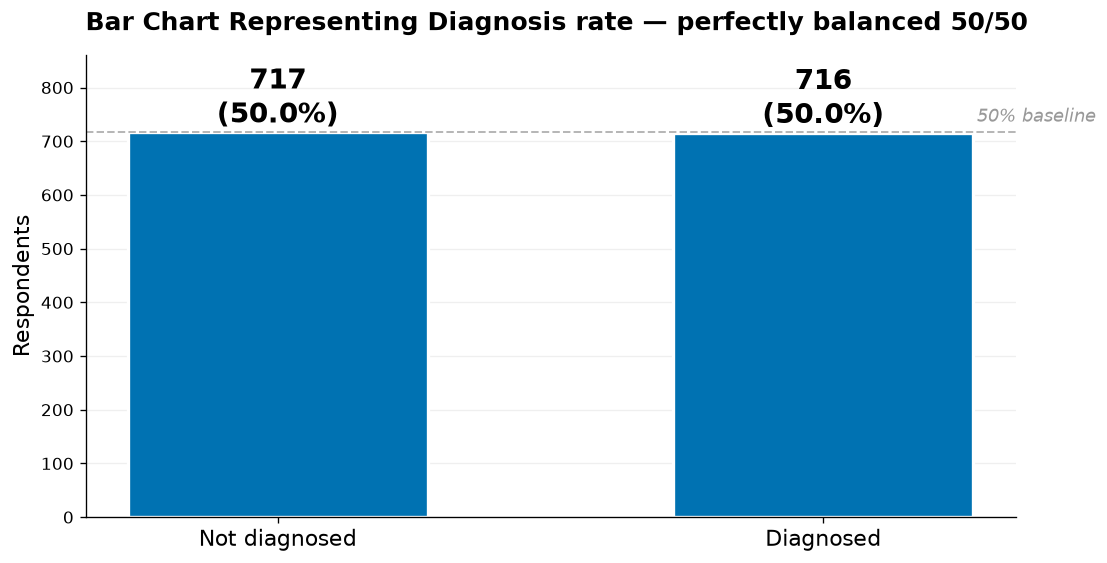

In [52]:
# PHASE 4 — CHART 1: DIAGNOSIS RATE

import matplotlib.pyplot as plt

TARGET = "have_you_been_diagnosed_with_a_51"   

vc = df[TARGET].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(range(len(vc)), vc.values,
              color="#0072B2", edgecolor="white", linewidth=2, width=0.55)

for bar, v in zip(bars, vc.values):
    pct = v / len(df) * 100
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
            f"{v:,}\n({pct:.1f}%)",
            ha="center", va="bottom", fontsize=17, fontweight="bold")

ax.axhline(len(df)/2, color="#999999", ls="--", lw=1.2, alpha=0.7)
ax.text(1.5, len(df)/2 + 20, "50% baseline",
        ha="right", fontsize=11, color="#999999", style="italic")

ax.set_xticks(range(len(vc)))
ax.set_xticklabels(["Not diagnosed", "Diagnosed"], fontsize=13)
ax.set_ylabel("Respondents", fontsize=13)
ax.set_title("Bar Chart Representing Diagnosis rate — perfectly balanced 50/50",
             loc="left", pad=15, fontsize=15)
ax.set_ylim(0, max(vc.values) * 1.2)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.savefig("phase4_01_diagnosis.png", dpi=150, bbox_inches="tight")
plt.show()

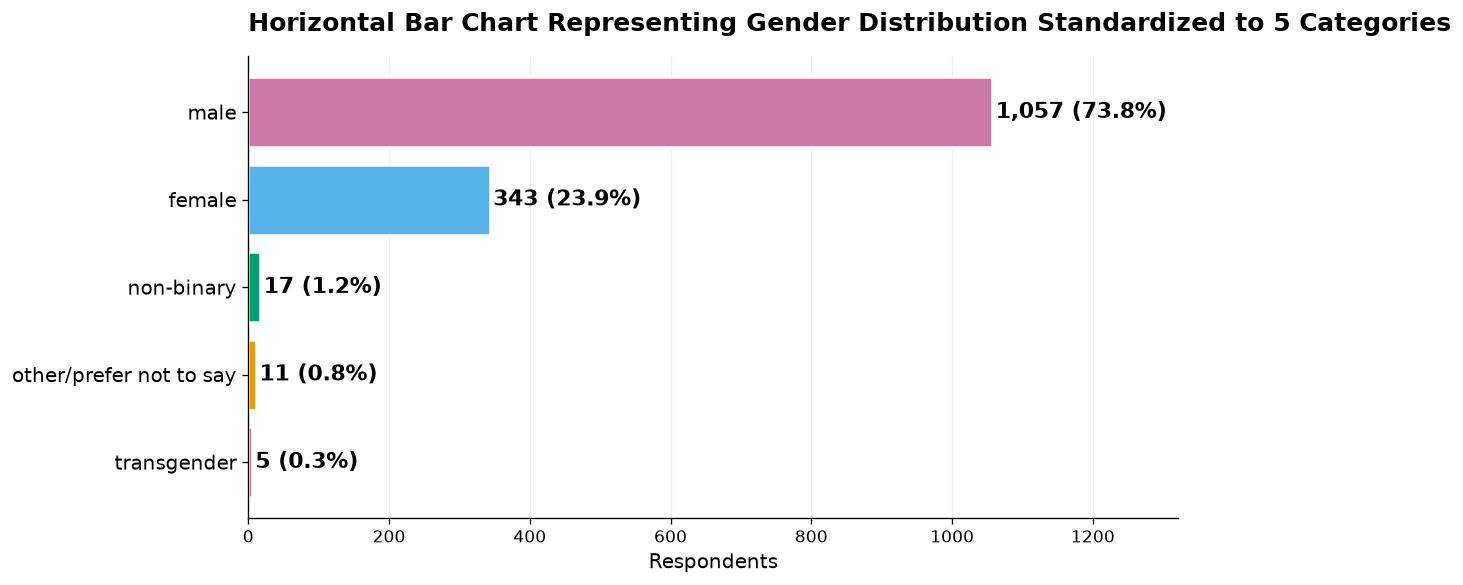

In [53]:
# PHASE 4 — CHART 2: GENDER DISTRIBUTION (after standardisation)

GENDER = "gender_detailed"

vc = df[GENDER].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(10, 5))

colors = ["#CC79A7", "#E69F00", "#009E73", "#56B4E9"][:len(vc)]
bars = ax.barh(range(len(vc)), vc.values,
               color=colors, edgecolor="white", linewidth=1.5)

for bar, v in zip(bars, vc.values):
    pct = v / len(df) * 100
    ax.text(bar.get_width() + 5, bar.get_y() + bar.get_height()/2,
            f"{v:,} ({pct:.1f}%)", va="center", fontsize=13, fontweight="bold")

ax.set_yticks(range(len(vc)))
ax.set_yticklabels(vc.index, fontsize=12)
ax.set_xlabel("Respondents", fontsize=12)
ax.set_title("Horizontal Bar Chart Representing Gender Distribution Standardized to 5 Categories",
             loc="left", pad=15, fontsize=15)
ax.set_xlim(0, vc.max() * 1.25)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.savefig("phase4_02_gender.png", dpi=150, bbox_inches="tight")
plt.show()

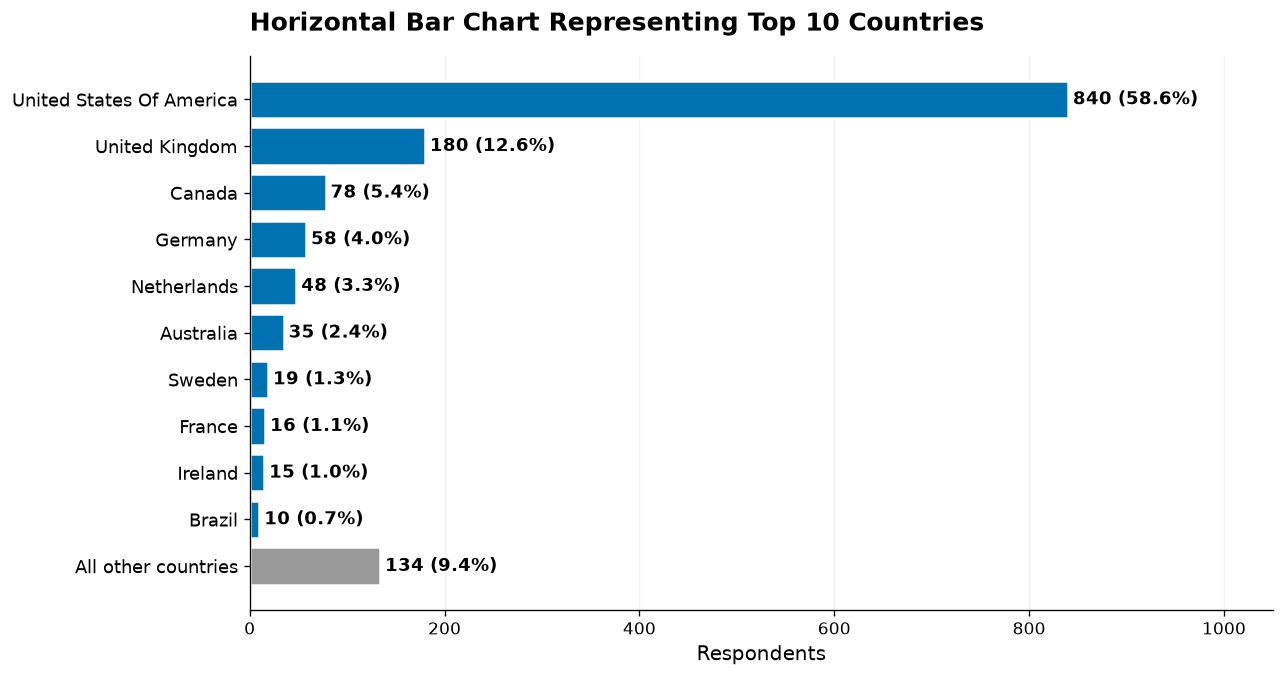

In [54]:
# PHASE 4 — CHART 3: TOP 10 COUNTRIES (from country_detailed)

import matplotlib.pyplot as plt

if "country_detailed" not in df.columns:
    raise ValueError("country_detailed missing — did the save step run?")

vc = df["country_detailed"].value_counts()

# top 10 + "other"
top_n = 10
top = vc.head(top_n)
others = vc.iloc[top_n:].sum()

labels = [str(c).title() for c in top.index] + ["All other countries"]
values = list(top.values) + [others]

fig, ax = plt.subplots(figsize=(11, 6))

colors = ["#0072B2"] * top_n + ["#999999"]
bars = ax.barh(range(len(labels)), values[::-1],
               color=colors[::-1], edgecolor="white", linewidth=1.5)

for bar, v in zip(bars, values[::-1]):
    pct = v / len(df) * 100
    ax.text(bar.get_width() + 5, bar.get_y() + bar.get_height()/2,
            f"{v:,} ({pct:.1f}%)", va="center",
            fontsize=11, fontweight="bold")

ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels[::-1], fontsize=11)
ax.set_xlabel("Respondents", fontsize=12)
ax.set_title("Horizontal Bar Chart Representing Top 10 Countries",
             loc="left", pad=15, fontsize=15)
ax.set_xlim(0, max(values) * 1.25)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.savefig("phase4_03_country.png", dpi=150, bbox_inches="tight")
plt.show()

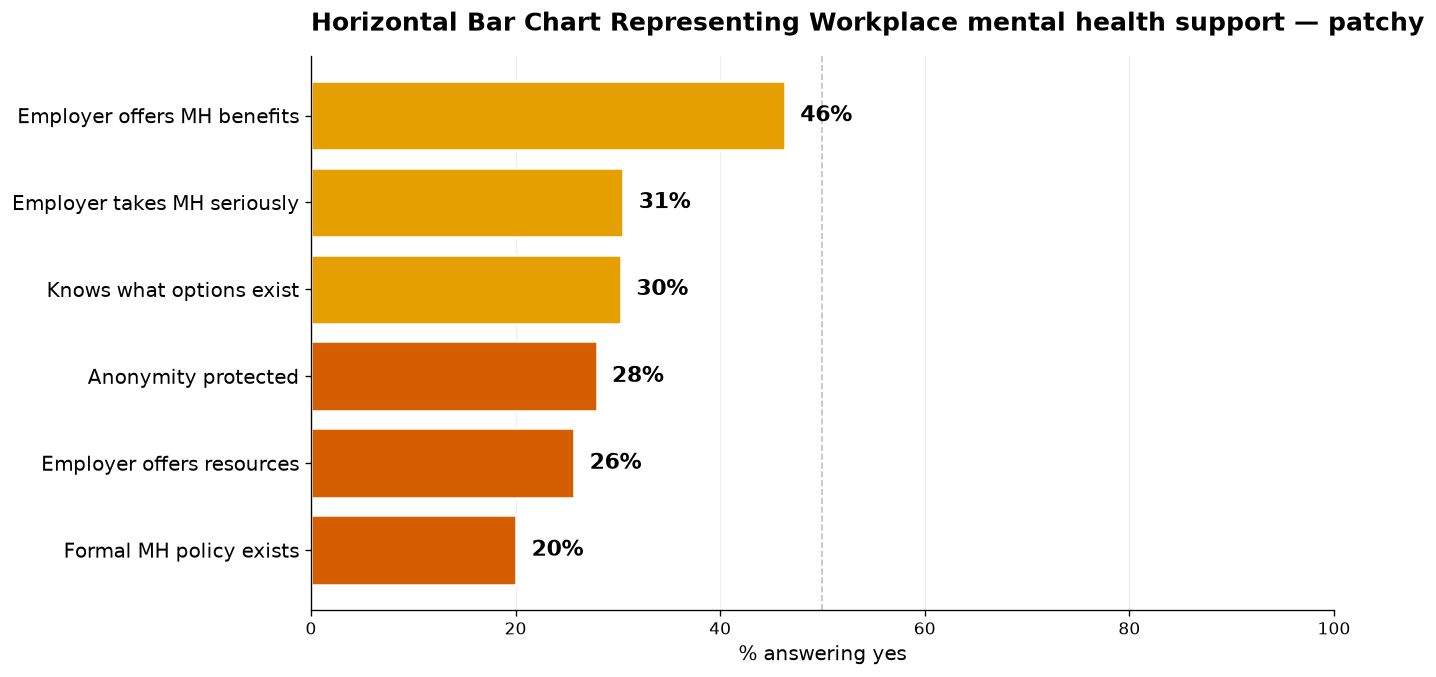

In [55]:
# PHASE 4 — CHART 4: WORKPLACE SUPPORT PREVALENCE

import pandas as pd
import matplotlib.pyplot as plt

# 1. Map raw column names to friendly labels
SUPPORT = {
    "does_your_employer_provide_men_5":   "Employer offers MH benefits",
    "do_you_know_the_options_for_me_6":   "Knows what options exist",
    "has_your_employer_ever_formall_7":   "Formal MH policy exists",
    "does_your_employer_offer_resou_8":   "Employer offers resources",
    "is_your_anonymity_protected_if_9":   "Anonymity protected",
    "do_you_feel_that_your_employer_15":  "Employer takes MH seriously",
}

rates = {}
for original_name, label in SUPPORT.items():
    detailed_col = f"{original_name}_detailed"
    
    # Check if the saved detailed column exists
    if detailed_col in df.columns:
        # Convert to string, lowercase, drop NaNs
        s = df[detailed_col].dropna().astype(str).str.lower()
        
        # Count how many answered yes or yes, always
        # (This covers both yn_map and anonymity_map)
        valid_responses = s[s != "unknown"] # ignore unknowns
        if len(valid_responses) > 0:
            yes_count = valid_responses.isin(["yes", "yes, always"]).mean()
            rates[label] = yes_count

# 2. Sort and Plot
rates = dict(sorted(rates.items(), key=lambda x: x[1]))

fig, ax = plt.subplots(figsize=(11, 6))
labels = list(rates.keys())
values = [rates[k] * 100 for k in labels]
colors = ["#D55E00" if v < 30 else "#E69F00" if v < 60 else "#009E73" for v in values]

bars = ax.barh(range(len(labels)), values,
               color=colors, edgecolor="white", linewidth=1.5)

for bar, v in zip(bars, values):
    ax.text(v + 1.5, bar.get_y() + bar.get_height()/2,
            f"{v:.0f}%", va="center", fontsize=13, fontweight="bold")

ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels, fontsize=12)
ax.set_xlabel("% answering yes", fontsize=12)
ax.set_title("Horizontal Bar Chart Representing Workplace mental health support — patchy",
             loc="left", pad=15, fontsize=15)
ax.set_xlim(0, 100)
ax.axvline(50, color="#999999", lw=1, ls="--", alpha=0.6)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.savefig("phase4_04_support.png", dpi=150, bbox_inches="tight")
plt.show()

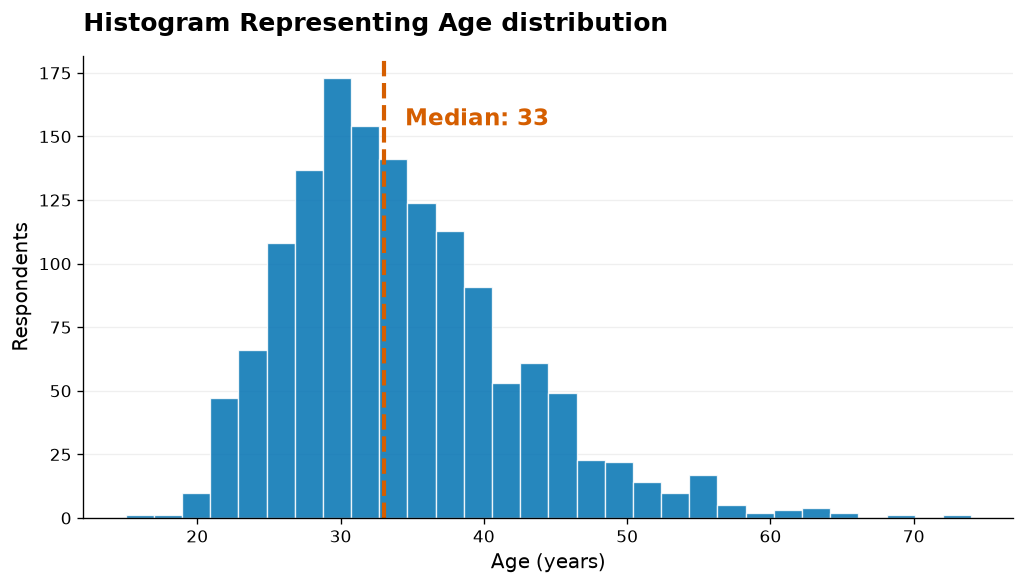

Median age: 33  |  IQR: 28–38


In [56]:
# PHASE 4 — CHART 5: AGE DISTRIBUTION (after capping 15–80)

AGE = "age_raw"

ages = pd.to_numeric(df[AGE], errors="coerce").dropna()

fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(ages, bins=30, color="#0072B2",
        edgecolor="white", linewidth=0.8, alpha=0.85)

med = ages.median()
ax.axvline(med, color="#D55E00", lw=2.5, ls="--")
ax.text(med + 1.5, ax.get_ylim()[1] * 0.85,
        f"Median: {med:.0f}",
        color="#D55E00", fontsize=14, fontweight="bold")

ax.set_xlabel("Age (years)", fontsize=12)
ax.set_ylabel("Respondents", fontsize=12)
ax.set_title("Histogram Representing Age distribution",
             loc="left", pad=15, fontsize=15)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.savefig("phase4_05_age.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Median age: {med:.0f}  |  IQR: {ages.quantile(0.25):.0f}–{ages.quantile(0.75):.0f}")





# PHASE 5

In [58]:
# 5.1 — BUILD FEATURE MATRIX 

import pandas as pd
import numpy as np

TARGET = "have_you_been_diagnosed_with_a_51"     # exclude from clustering, the outcome is used to validate clusters 


PROFILE_ONLY = [c for c in ["gender_detailed", "what_is_your_gender_57"]   # excude from clustering 
                if c in df.columns]                                        # descriptive columns used only to describe clusters after.
                                                                           
TFIDF_COLS   = [c for c in df.columns if "tfidf" in c.lower()]            # exclude from clustering because they'd dominate distances. 
                                                                          # Not profile variables because they're not used to describe clusters. Just excluded.
# ─────────────────────────────────────────────────────────────
# CLUSTERING FEATURES — the columns K-means will use
# ─────────────────────────────────────────────────────────────
# Keep a column only if ALL FOUR conditions are true:
#   1. NOT the target (target is for validation, not clustering)
#   2. NOT a profile-only column (used to describe clusters later)
#   3. NOT a TF-IDF column (text would dominate distances)
#   4. MUST be numeric (K-means can't process strings)
# ─────────────────────────────────────────────────────────────
feature_cols_no_text = [
    c for c in df.columns
    if c not in ([TARGET] + PROFILE_ONLY + TFIDF_COLS)   # 1, 2, 3
    and pd.api.types.is_numeric_dtype(df[c])              # 4
]

# ─────────────────────────────────────────────────────────────
# TYPE BREAKDOWN — just for reporting / understanding the mix
# (all three are still clustering features — this is only a label)
# ─────────────────────────────────────────────────────────────

# BINARY — a column whose only values are 0 and 1
#   Example: role_hr, what_is_your_gender__male
#   Note: set(...).issubset({0,1}) is true even for columns with only {0}
#   or only {1} — but constant columns get caught later by the NaN check
BINARY_COLS  = [c for c in feature_cols_no_text
                if set(df[c].dropna().unique()).issubset({0, 1})]

# ORDINAL — a column ending in _enc
#   These came from Phase 3: ordered text → ordered integers
#   Example: if_a_mental_health_issue_promp_10_enc  (0–4 scale)
ORDINAL_COLS = [c for c in feature_cols_no_text
                if c.endswith("_enc")]

# NUMERIC — everything left over
#   Continuous columns (like age)
#   "not in BINARY and not in ORDINAL" = everything else
NUMERIC_COLS = [c for c in feature_cols_no_text
                if c not in BINARY_COLS and c not in ORDINAL_COLS]

print("=" * 55)
print("FEATURE BREAKDOWN")
print("=" * 55)
print(f"  binary:   {len(BINARY_COLS):>3}")
print(f"  ordinal:  {len(ORDINAL_COLS):>3}")
print(f"  numeric:  {len(NUMERIC_COLS):>3}")
print(f"  tfidf:    {len(TFIDF_COLS):>3}   (excluded)")
print("  " + "─" * 28)
print(f"  total:    {len(df.select_dtypes('number').columns):>3}   (all numeric)")
print(f"  clustering: {len(feature_cols_no_text):>3}   (excl. target/profile/tfidf)")
print()
# ─── EXCLUSIONS — explicit audit ───
print("=" * 55)
print("EXCLUDED FROM CLUSTERING")
print("=" * 55)
print(f"  🎯 target (validation only):")
print(f"     • {TARGET}")
print()
print(f"  📊 profile only (for describing clusters):")
for c in PROFILE_ONLY:
    print(f"     • {c}")
print()
print(f"  🚫 tfidf (would dominate distances): {len(TFIDF_COLS)} columns")
print()

# ── build matrix ──
X_cluster = df[feature_cols_no_text]

# ── verify no NaN ──
nans = X_cluster.isna().sum()
nans = nans[nans > 0]

if len(nans):
    print(f"⚠ {len(nans)} columns have NaN — fix in Phase 3 first:")
    print(nans.to_string())
else:
    print("✅ no NaN in clustering matrix")

print(f"\nFeature matrix shape: {X_cluster.shape}")

FEATURE BREAKDOWN
  binary:    20
  ordinal:   36
  numeric:    2
  tfidf:     40   (excluded)
  ────────────────────────────
  total:     99   (all numeric)
  clustering:  58   (excl. target/profile/tfidf)

EXCLUDED FROM CLUSTERING
  🎯 target (validation only):
     • have_you_been_diagnosed_with_a_51

  📊 profile only (for describing clusters):
     • gender_detailed

  🚫 tfidf (would dominate distances): 40 columns

✅ no NaN in clustering matrix

Feature matrix shape: (1433, 58)


In [59]:
# ═══════════════════════════════════════════════════════════
# 5.2a — SCALE FOR CLUSTERING (drop rare binaries, then scale)
# ═══════════════════════════════════════════════════════════
# Input:  feature_cols_no_text (from 5.1), df
# Output: feature_cols_final    (feature list without rare binaries)
#         X_scaled              (scaled matrix for K-means)
# ═══════════════════════════════════════════════════════════
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd

# ── Step 1: identify rare binaries ──
# A binary whose positive rate is <5% or >95% will inflate after
# scaling (z-score ±10). We exclude them from clustering but keep
# them in df for post-cluster profiling.
BINARY_ALL = [c for c in feature_cols_no_text
              if set(df[c].dropna().unique()).issubset({0, 1})]

RARE_BINARIES = [c for c in BINARY_ALL
                 if df[c].mean() < 0.05 or df[c].mean() > 0.95]

if RARE_BINARIES:
    print(f"⚠ Dropping {len(RARE_BINARIES)} rare binaries from clustering:")
    for c in RARE_BINARIES:
        print(f"  • {c:<50} rate = {df[c].mean():.3f}")
    print("  (kept in df for post-cluster profiling)")
else:
    print("✅ No rare binaries — scaling all features")

# ── Step 2: final feature list ──
feature_cols_final = [c for c in feature_cols_no_text
                      if c not in RARE_BINARIES]

# ── Step 3: verify no NaN ──
# K-means cannot handle NaN; if any remain, they must be imputed
# in Phase 3 — do NOT silently fill with 0 (that corrupts ordinals)
X_cluster = df[feature_cols_final]
nans = X_cluster.isna().sum()
nans = nans[nans > 0]

if len(nans):
    raise ValueError(f"NaN present — fix in Phase 3 first:\n{nans}")

# ── Step 4: scale everything ──
# All features on equal footing: mean=0, std=1
# Needed because ordinals (0–4) would otherwise dominate binaries (0–1)
scaler   = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

# ── Step 5: verify scaling worked ──
print(f"\nScaling results:")
print(f"  matrix shape:   {X_scaled.shape}")
print(f"  mean max |μ|:   {np.abs(X_scaled.mean(axis=0)).max():.2e}   (≈0)")
print(f"  std min:        {X_scaled.std(axis=0).min():.4f}   (≈1)")

⚠ Dropping 1 rare binaries from clustering:
  • what_is_your_gender__other                         rate = 0.023
  (kept in df for post-cluster profiling)

Scaling results:
  matrix shape:   (1433, 57)
  mean max |μ|:   3.94e-16   (≈0)
  std min:        1.0000   (≈1)


In [60]:
# 5.4 — CHOOSE K (on the 57-feature X_scaled)

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

K_RANGE = range(2, 11)
inertias, sil_scores, db_scores = [], [], []

for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels, sample_size=2000, random_state=42))
    db_scores.append(davies_bouldin_score(X_scaled, labels))
    print(f"K={k:>2}  inertia={km.inertia_:>10.0f}  "
          f"silhouette={sil_scores[-1]:.3f}  "
          f"davies_bouldin={db_scores[-1]:.3f}")

best_k = K_RANGE[sil_scores.index(max(sil_scores))]
print(f"\n🎯 Best K by silhouette: {best_k}  (score = {max(sil_scores):.3f})")

K= 2  inertia=     71742  silhouette=0.155  davies_bouldin=2.090
K= 3  inertia=     67225  silhouette=0.095  davies_bouldin=2.930
K= 4  inertia=     64855  silhouette=0.084  davies_bouldin=3.031
K= 5  inertia=     63384  silhouette=0.076  davies_bouldin=3.148
K= 6  inertia=     62109  silhouette=0.073  davies_bouldin=3.071
K= 7  inertia=     61131  silhouette=0.069  davies_bouldin=3.239
K= 8  inertia=     60318  silhouette=0.051  davies_bouldin=3.456
K= 9  inertia=     59413  silhouette=0.054  davies_bouldin=3.307
K=10  inertia=     58635  silhouette=0.055  davies_bouldin=3.174

🎯 Best K by silhouette: 2  (score = 0.155)


In [61]:
# 5.2b — IMPROVE SILHOUETTE (test 6 strategies, pick best)
# Problem: silhouette with all features was 0.155 (weak)
# Solution: try 6 strategies, pick best silhouette + interpretability

import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.feature_selection import mutual_info_classif
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA

X_baseline = X_scaled.copy()   # 57 features from 5.2

def evaluate(X_data, k_range=range(2, 8), use_gmm=False):
    """Return (best_silhouette, best_k) by trying K=2..7."""
    scores = {}
    for k in k_range:
        model = (GaussianMixture(n_components=k, random_state=42, n_init=5)
                 if use_gmm else
                 KMeans(n_clusters=k, n_init=10, random_state=42))
        labels = model.fit_predict(X_data)
        if len(set(labels)) < 2:
            continue
        scores[k] = silhouette_score(X_data, labels,
                                      sample_size=2000, random_state=42)
    if not scores:
        return None, None
    best_k = max(scores, key=scores.get)
    return scores[best_k], best_k

results = {}

# ── Strategy 1: baseline ──
sil, k = evaluate(X_baseline)
results["baseline (all features)"] = (sil, k)
print(f"baseline:              K={k}, silhouette={sil:.3f}")

# ── Strategy 2: remove dominating feature ──
feats_fix1 = [c for c in feature_cols_final if c != "are_you_self_employed_1"]
X_fix1 = StandardScaler().fit_transform(df[feats_fix1].fillna(0))
sil, k = evaluate(X_fix1)
results["remove are_you_self_employed_1"] = (sil, k)
print(f"remove self-employed:  K={k}, silhouette={sil:.3f}")

# ── Strategy 3: top-K features by mutual information ──
mi = mutual_info_classif(df[feats_fix1].fillna(0),
                         df[TARGET].fillna(0), random_state=42)
mi_df = (pd.DataFrame({"feature": feats_fix1, "mi": mi})
         .sort_values("mi", ascending=False))

for top_k in [15, 20, 30]:
    top_feats = mi_df.head(top_k)["feature"].tolist()
    X_top = StandardScaler().fit_transform(df[top_feats].fillna(0))
    sil, k = evaluate(X_top)
    results[f"top-{top_k} features (MI)"] = (sil, k)
    print(f"top-{top_k} features:      K={k}, silhouette={sil:.3f}")

# ── Strategy 4: top-20 features + GMM ──
top20 = mi_df.head(20)["feature"].tolist()
X_top20 = StandardScaler().fit_transform(df[top20].fillna(0))
sil, k = evaluate(X_top20, use_gmm=True)
results["top-20 + GMM"] = (sil, k)
print(f"top-20 + GMM:          K={k}, silhouette={sil:.3f}")

# ── Strategy 5: PCA to 10 components ──
X_pca10 = PCA(n_components=10, random_state=42).fit_transform(X_baseline)
sil, k = evaluate(X_pca10)
results["PCA-10 components"] = (sil, k)
print(f"PCA-10:                K={k}, silhouette={sil:.3f}")

# ── Strategy 6: remove correlated features (|r| > 0.7) ──
corr = df[feats_fix1].corr().abs()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
upper = corr.where(mask).stack().sort_values(ascending=False)
to_drop = set()
for (a, b), r in upper[upper > 0.7].items():
    if a not in to_drop and b not in to_drop:
        to_drop.add(b)
feats_uncorr = [c for c in feats_fix1 if c not in to_drop]
X_uncorr = StandardScaler().fit_transform(df[feats_uncorr].fillna(0))
sil, k = evaluate(X_uncorr)
results["remove correlated (r>0.7)"] = (sil, k)
print(f"remove correlated:     K={k}, silhouette={sil:.3f}")

# ── Comparison table ──
print("\n" + "=" * 62)
print("SILHOUETTE COMPARISON")
print("=" * 62)
print(f"{'strategy':<32} {'best K':>7} {'silhouette':>12}")
print("-" * 62)
best_overall = max(results, key=lambda x: results[x][0])
for name, (sil, k) in sorted(results.items(), key=lambda x: -x[1][0]):
    marker = " 🏆" if name == best_overall else ""
    print(f"{name:<32} {k:>7} {sil:>12.3f}{marker}")

best_sil, best_k = results[best_overall]
print(f"\n🏆 Best strategy: {best_overall}")
print(f"   K = {best_k},  silhouette = {best_sil:.3f}")

baseline:              K=2, silhouette=0.155
remove self-employed:  K=2, silhouette=0.135
top-15 features:      K=2, silhouette=0.214
top-20 features:      K=2, silhouette=0.168
top-30 features:      K=3, silhouette=0.126
top-20 + GMM:          K=2, silhouette=0.159
PCA-10:                K=2, silhouette=0.286
remove correlated:     K=2, silhouette=0.107

SILHOUETTE COMPARISON
strategy                          best K   silhouette
--------------------------------------------------------------
PCA-10 components                      2        0.286 🏆
top-15 features (MI)                   2        0.214
top-20 features (MI)                   2        0.168
top-20 + GMM                           2        0.159
baseline (all features)                2        0.155
remove are_you_self_employed_1         2        0.135
top-30 features (MI)                   3        0.126
remove correlated (r>0.7)              2        0.107

🏆 Best strategy: PCA-10 components
   K = 2,  silhouette = 0.286


In [62]:
# 5.2c — ADOPT WINNING STRATEGY (PCA-10)
# From 5.2b: PCA-10 won with silhouette ~0.286
# This cell transforms X_scaled to 10 PCs — the actual commit.
# After this cell: X_scaled has shape (1433, 10)

from sklearn.decomposition import PCA
import numpy as np

pca_final = PCA(n_components=10, random_state=42)
X_pca = pca_final.fit_transform(X_scaled)

print(f"PCA-10 adopted: {X_scaled.shape[1]} features → {X_pca.shape[1]} components")
print(f"Variance preserved: {pca_final.explained_variance_ratio_.sum():.1%}")

# REPLACE X_scaled with the 10-PC matrix
X_scaled = X_pca

print(f"\nX_scaled now: {X_scaled.shape}")
print(f"feature_cols_final still holds {len(feature_cols_final)} original names (for profiling)")

PCA-10 adopted: 57 features → 10 components
Variance preserved: 52.1%

X_scaled now: (1433, 10)
feature_cols_final still holds 57 original names (for profiling)


In [63]:
# 5.3 — PCA VARIANCE + 2D EMBEDDING (for visualization)
# X_scaled is now 10 PCs (from 5.2c)
# This cell: (a) reports how many PCs we have, (b) makes 2D plot

from sklearn.decomposition import PCA

# ─── Step 1: how many components do we have? ───
print(f"X_scaled shape: {X_scaled.shape}  (already PCA-10 from 5.2c)")
print(f"variance explained: {pca_final.explained_variance_ratio_.sum():.1%}")
print()

# ─── Step 2: 2D embedding for plotting ───
# X_2d = (1433, 2) — one (PC1, PC2) coordinate per respondent
pca2 = PCA(n_components=2, random_state=42)
X_2d = pca2.fit_transform(X_scaled)

print(f"2D embedding (PC1+PC2) explains "
      f"{pca2.explained_variance_ratio_.sum():.1%} of PCA variance")

X_scaled shape: (1433, 10)  (already PCA-10 from 5.2c)
variance explained: 52.1%

2D embedding (PC1+PC2) explains 43.4% of PCA variance


# PHASE 6

In [65]:
# 5.4 — CHOOSE K (on PCA-10 matrix) How many clusters (K) should I use for the final model?
# X_scaled is now 10 PCs → silhouette landscape differs from baseline

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

K_RANGE = range(2, 11)
inertias, sil_scores, db_scores = [], [], []

for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels,
                                       sample_size=2000, random_state=42))
    db_scores.append(davies_bouldin_score(X_scaled, labels))
    print(f"K={k:>2}  inertia={km.inertia_:>10.0f}  "
          f"silhouette={sil_scores[-1]:.3f}  "
          f"davies_bouldin={db_scores[-1]:.3f}")

best_k = K_RANGE[sil_scores.index(max(sil_scores))]
print(f"\n🎯 Best K = {best_k}  (silhouette = {max(sil_scores):.3f})")

K= 2  inertia=     32619  silhouette=0.286  davies_bouldin=1.372
K= 3  inertia=     28134  silhouette=0.192  davies_bouldin=1.864
K= 4  inertia=     25798  silhouette=0.173  davies_bouldin=1.872
K= 5  inertia=     24370  silhouette=0.161  davies_bouldin=1.916
K= 6  inertia=     23276  silhouette=0.150  davies_bouldin=1.940
K= 7  inertia=     22289  silhouette=0.129  davies_bouldin=2.081
K= 8  inertia=     21555  silhouette=0.129  davies_bouldin=2.051
K= 9  inertia=     20829  silhouette=0.124  davies_bouldin=2.033
K=10  inertia=     20258  silhouette=0.127  davies_bouldin=2.004

🎯 Best K = 2  (silhouette = 0.286)


In [66]:
# 5.5 — FIT FINAL KMEANS

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

K = best_k

km_final = KMeans(n_clusters=K, n_init=20, random_state=42)
df["cluster"] = km_final.fit_predict(X_scaled)

# ─── cluster sizes ───
sizes = df["cluster"].value_counts().sort_index()
print(f"Final clustering: K={K}\n")
print(f"{'cluster':>8} {'count':>7} {'pct':>7}")
print("-" * 25)
for k, n in sizes.items():
    print(f"{k:>8} {n:>7} {n/len(df)*100:>6.1f}%")

# ─── final silhouette ───
final_sil = silhouette_score(X_scaled, df["cluster"],
                              sample_size=2000, random_state=42)
print(f"\nFinal silhouette: {final_sil:.3f}")

Final clustering: K=2

 cluster   count     pct
-------------------------
       0    1146   80.0%
       1     287   20.0%

Final silhouette: 0.286


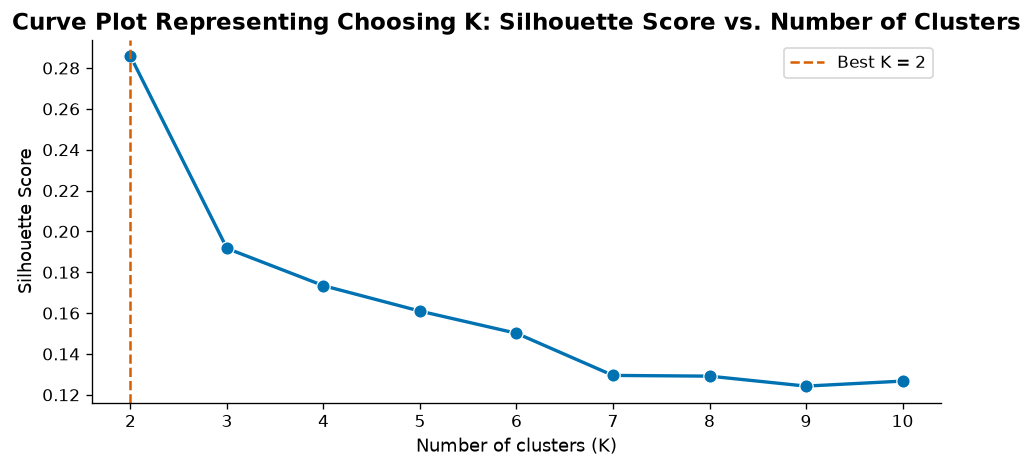

In [67]:
# PHASE 5 - CHART 1: Silhouette Curve

import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Seaborn works best with a DataFrame, so we create one for the plot
sil_df = pd.DataFrame({
    'K': list(K_RANGE),
    'Silhouette': sil_scores
})

plt.figure(figsize=(8, 4))

# Draw the line and markers using sns.lineplot
sns.lineplot(data=sil_df, x='K', y='Silhouette', 
             marker='o', color='#0072B2', linewidth=2, markersize=8)

# Add the vertical line for the best K
plt.axvline(best_k, color='#D55E00', linestyle='--', label=f'Best K = {best_k}')

plt.xlabel('Number of clusters (K)')
plt.ylabel('Silhouette Score')
plt.title('Curve Plot Representing Choosing K: Silhouette Score vs. Number of Clusters')
plt.legend()
plt.tight_layout()
plt.savefig("phase5_01_silhouette_curve.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close()

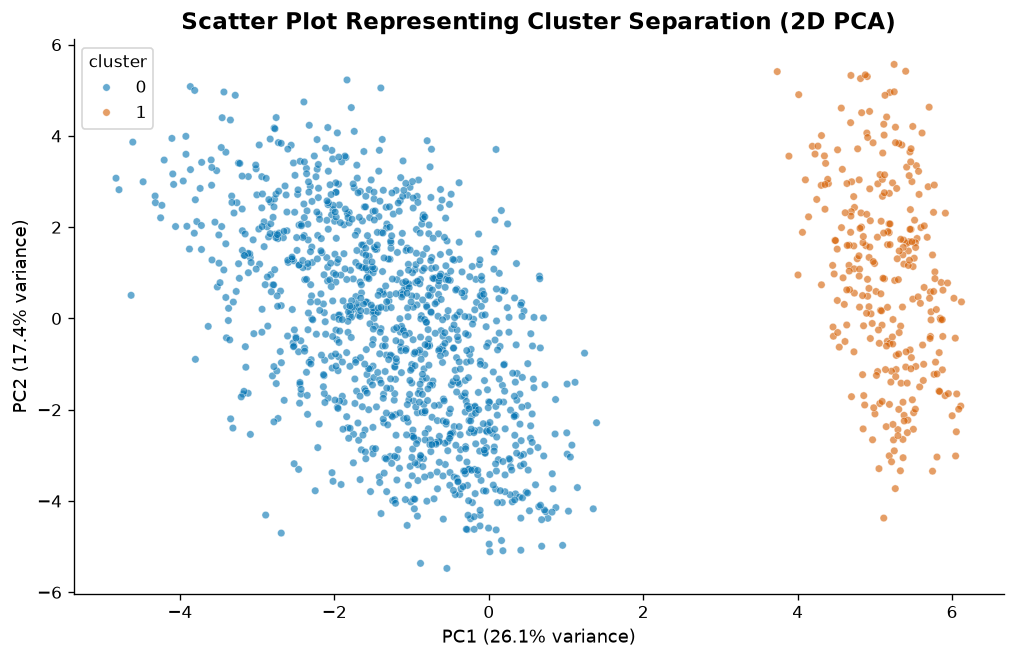

In [68]:
# PHASE 5 - CHART 2: 2D Scatter (Cluster separationusing X_2d)

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.scatterplot(x=X_2d[:, 0], y=X_2d[:, 1], hue=df['cluster'], 
                palette=['#0072B2', '#D55E00'], alpha=0.6, s=20)
plt.xlabel(f"PC1 ({pca2.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({pca2.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.title("Scatter Plot Representing Cluster Separation (2D PCA)")
plt.savefig("phase5_02_pca_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

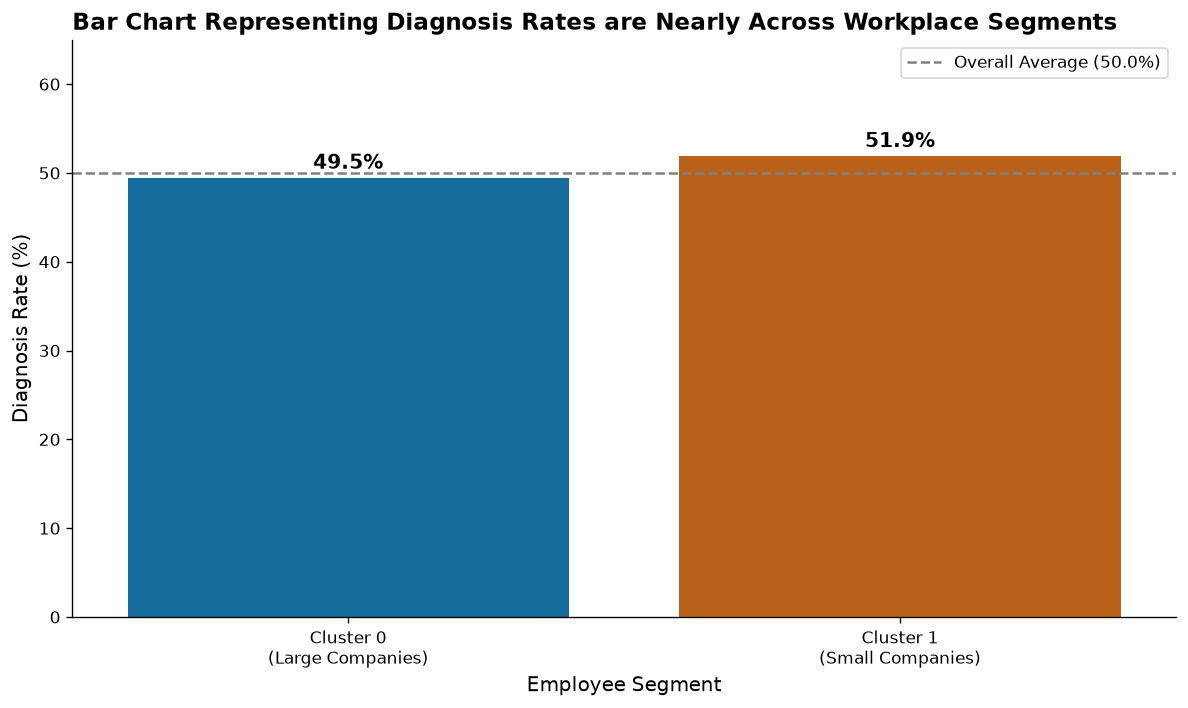

In [69]:
# PHASE 5 - CHART 3: Diagnosis Bar Chart

import seaborn as sns
import matplotlib.pyplot as plt

# 1. Create descriptive names for the clusters based on your Phase 6 findings
cluster_names = {
    0: "Cluster 0\n(Large Companies)",
    1: "Cluster 1\n(Small Companies)"
}
df['cluster_label'] = df['cluster'].map(cluster_names)

# 2. Calculate the rates
rates = df.groupby('cluster_label')[TARGET].mean() * 100
# Sort so Large Companies is on the left, Small on the right
rates = rates.sort_index() 

plt.figure(figsize=(10, 6))

# 3. Plot
ax = sns.barplot(
    x=rates.index, 
    y=rates.values, 
    hue=rates.index, 
    palette=['#0072B2', '#D55E00'], 
    legend=False
)

# 4. Add the overall average line
overall_avg = df[TARGET].mean() * 100
plt.axhline(overall_avg, color='gray', linestyle='--', label=f'Overall Average ({overall_avg:.1f}%)')

# 5. Add the percentage labels on top of the bars
for i, v in enumerate(rates.values):
    ax.text(i, v + 1, f"{v:.1f}%", ha='center', fontweight='bold', fontsize=12)

# 6. Add clear labels and title
plt.ylabel('Diagnosis Rate (%)', fontsize=12)
plt.xlabel('Employee Segment', fontsize=12)
plt.title('Bar Chart Representing Diagnosis Rates are Nearly Across Workplace Segments', loc='left', fontweight='bold', fontsize=14)
plt.ylim(0, 65)
plt.legend(loc='upper right')
plt.tight_layout()

# Save and show
plt.savefig("phase5_03_diagnosis_bar.png", dpi=150, bbox_inches="tight")
plt.show()

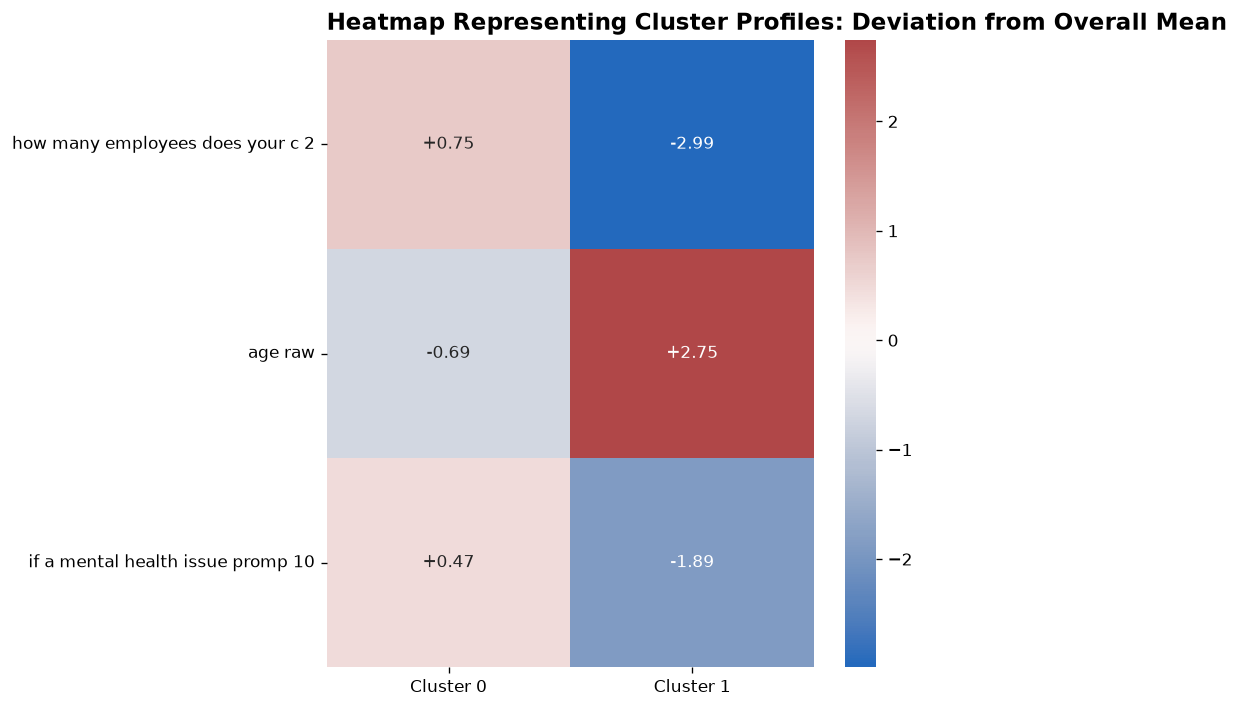

In [70]:
# PHASE 6 - CHART 1: Cluster Profile Heatmap (Interpretation)

import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# ─── 1. Recompute the top features per cluster ───
overall_mean = df[feature_cols_final].mean()

top_feats = []
for k in range(K):
    mask = df["cluster"] == k
    cluster_mean = df.loc[mask, feature_cols_final].mean()
    diff = (cluster_mean - overall_mean).abs().sort_values(ascending=False).head(3)
    top_feats.extend(diff.index.tolist())

# Deduplicate and keep top 8
top_feats = list(dict.fromkeys(top_feats))[:8]

# ─── 2. Build the heatmap matrix (deviation from mean) ───
heatmap_data = []
for feat in top_feats:
    row = [df.loc[df["cluster"] == k, feat].mean() - overall_mean[feat]
           for k in range(K)]
    heatmap_data.append(row)
heatmap_data = np.array(heatmap_data)

# ─── 3. Plot ───
plt.figure(figsize=(8, 6))
sns.heatmap(
    heatmap_data,
    annot=True, fmt="+.2f",
    cmap="vlag", center=0,
    xticklabels=[f"Cluster {k}" for k in range(K)],
    yticklabels=[c.replace("_enc", "").replace("_", " ")[:40] for c in top_feats]
)
plt.title("Heatmap Representing Cluster Profiles: Deviation from Overall Mean", loc="left", fontweight="bold")
plt.tight_layout()
plt.savefig("phase6_01_cluster_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close()